In [ ]:
!pip install plotly -q
import torch
print(f'PyTorch: {torch.__version__}')
print(f'GPU: {torch.cuda.is_available()}')

PyTorch: 2.10.0+cu128
GPU: True


In [ ]:
"""
Track B — SMARD National PV Forecasting
Hourly ML Benchmark Pipeline
=============================================
Input   : germany_pv_weather_dataset_2019_2024.csv (hourly)
Target  : pv_mwh at hour t+1 (next-hour ahead forecast)
Models  : Persistence, Linear Regression, Ridge Regression,
          Random Forest, Extra Trees, XGBoost, LightGBM,
          HistGradientBoosting
Split   : 70% train / 15% val / 15% test (chronological)
Night   : Train on all hours, evaluate on daytime only
          (solar zenith angle < 85 degrees)
Metrics : R², RMSE, MAE, nRMSE on daytime test hours
Plots   : Interactive Plotly HTML files
No leakage. No post-hoc night zeroing. Honest metrics.

Google Colab ready — set COLAB = True to save to Drive
"""

import pandas as pd
import numpy as np
import warnings
import time
import os
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (RandomForestRegressor,
                              ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb
import lightgbm as lgb
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ─────────────────────────────────────────────
# 0. CONFIGURATION
# ─────────────────────────────────────────────
INPUT_FILE  = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/germany_pv_weather_dataset_2019_2024.csv"
COLAB       = True
DRIVE_PATH  = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)"
OUTPUT_DIR  = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model"
DATE_START  = "2019-01-01"
DATE_END    = "2024-12-31"
TRAIN_FRAC  = 0.70
VAL_FRAC    = 0.15
RANDOM_SEED = 42
ZENITH_THRESHOLD = 85.0   # degrees — daytime definition

np.random.seed(RANDOM_SEED)

print("=" * 65)
print("  TRACK B — HOURLY ML BENCHMARK PIPELINE")
print("=" * 65)

# ─────────────────────────────────────────────
# COLAB SETUP
# ─────────────────────────────────────────────
if COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_PATH, exist_ok=True)
    print(f"  Output directory: {DRIVE_PATH}")

pipeline_start = time.time()

# ─────────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────────
print("\n[1] Loading hourly dataset...")

df = pd.read_csv(INPUT_FILE)
print(f"    Raw shape  : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"    Columns    : {list(df.columns)}")

# ─────────────────────────────────────────────
# 2. PARSE TIMESTAMP
# ─────────────────────────────────────────────
print("\n[2] Parsing timestamps...")

ts_col = None
for col in df.columns:
    if any(k in col.lower() for k in ["time", "date", "start", "datum"]):
        ts_col = col
        break
if ts_col is None:
    ts_col = df.columns[0]
print(f"    Timestamp column : {ts_col}")

df["timestamp"] = pd.to_datetime(df[ts_col], utc=True, errors="coerce")
if df["timestamp"].isna().all():
    df["timestamp"] = pd.to_datetime(df[ts_col], errors="coerce")

tz = df["timestamp"].dt.tz
if tz is not None:
    df["timestamp"] = df["timestamp"].dt.tz_convert("Europe/Berlin")
else:
    df["timestamp"] = df["timestamp"].dt.tz_localize("Europe/Berlin",
                                                       ambiguous="NaT",
                                                       nonexistent="NaT")

df = df.dropna(subset=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# Filter date range
df = df[
    (df["timestamp"] >= pd.Timestamp(DATE_START, tz="Europe/Berlin")) &
    (df["timestamp"] <= pd.Timestamp(DATE_END + " 23:59:59",
                                      tz="Europe/Berlin"))
].reset_index(drop=True)

print(f"    Range : {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"    Rows  : {len(df):,}")

# ─────────────────────────────────────────────
# 3. DETECT COLUMNS
# ─────────────────────────────────────────────
pv_col    = "pv_mwh"
ghi_col   = "ghi"              if "ghi"             in df.columns else None
dni_col   = "dni"              if "dni"             in df.columns else None
dhi_col   = "dhi"              if "dhi"             in df.columns else None
temp_col  = "temp_air"         if "temp_air"        in df.columns else None
wind_col  = "wind_speed_kmh"   if "wind_speed_kmh"  in df.columns else None
cloud_col = ("cloud_cover_pct" if "cloud_cover_pct" in df.columns
             else "cloud_cover" if "cloud_cover"    in df.columns else None)

print(f"\n    PV column    : {pv_col}")
print(f"    GHI column   : {ghi_col}")
print(f"    Temp column  : {temp_col}")
print(f"    Wind column  : {wind_col}")
print(f"    Cloud column : {cloud_col}")

# ─────────────────────────────────────────────
# 4. SOLAR ZENITH ANGLE (night suppression)
# ─────────────────────────────────────────────
print("\n[3] Computing solar zenith angle for Germany centroid...")

# Germany centroid: 51.2°N, 10.4°E
LAT_RAD = np.radians(51.2)

def compute_solar_zenith(timestamps):
    """
    Simplified solar zenith angle for Germany centroid.
    Accurate enough for daytime/night classification.
    Uses NOAA solar position algorithm approximation.
    """
    ts_utc = timestamps.dt.tz_convert("UTC")
    doy    = ts_utc.dt.dayofyear
    hour   = ts_utc.dt.hour + ts_utc.dt.minute / 60.0

    # Solar declination (degrees → radians)
    decl = np.radians(23.45 * np.sin(np.radians(360 / 365 * (doy - 81))))

    # Hour angle: solar noon at 10.4°E = UTC + 10.4/15 hours
    lon_offset = 10.4 / 15.0
    hour_angle = np.radians(15.0 * (hour + lon_offset - 12.0))

    # Zenith angle
    cos_z = (np.sin(LAT_RAD) * np.sin(decl) +
             np.cos(LAT_RAD) * np.cos(decl) * np.cos(hour_angle))
    cos_z = np.clip(cos_z, -1.0, 1.0)
    zenith = np.degrees(np.arccos(cos_z))
    return zenith

df["solar_zenith"] = compute_solar_zenith(df["timestamp"])
df["is_daytime"]   = df["solar_zenith"] < ZENITH_THRESHOLD

n_day   = df["is_daytime"].sum()
n_night = (~df["is_daytime"]).sum()
print(f"    Daytime hours  : {n_day:,} ({100*n_day/len(df):.1f}%)")
print(f"    Nighttime hours: {n_night:,} ({100*n_night/len(df):.1f}%)")

# ─────────────────────────────────────────────
# 5. FEATURE ENGINEERING
# ─────────────────────────────────────────────
print("\n[4] Engineering features (leak-free at hour t)...")

# ── Calendar features (cyclic) ──
hour         = df["timestamp"].dt.hour
doy          = df["timestamp"].dt.dayofyear
month        = df["timestamp"].dt.month
weekday      = df["timestamp"].dt.weekday

df["hour_sin"]    = np.sin(2 * np.pi * hour / 24)
df["hour_cos"]    = np.cos(2 * np.pi * hour / 24)
df["doy_sin"]     = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"]     = np.cos(2 * np.pi * doy / 365.25)
df["month_sin"]   = np.sin(2 * np.pi * month / 12)
df["month_cos"]   = np.cos(2 * np.pi * month / 12)
df["is_weekend"]  = (weekday >= 5).astype(int)

# ── Solar position features ──
df["zenith_cos"]  = np.cos(np.radians(df["solar_zenith"].clip(0, 90)))
df["zenith_sin"]  = np.sin(np.radians(df["solar_zenith"].clip(0, 90)))

# ── PV lag features (hourly) ──
# t-1: previous hour
# t-24: same hour yesterday (persistence)
# t-48: same hour 2 days ago
# t-168: same hour last week
for lag in [1, 2, 3, 24, 48, 168]:
    df[f"pv_lag_{lag}"] = df[pv_col].shift(lag)

# ── PV rolling statistics (shift(1) to prevent leakage) ──
df["pv_roll24_mean"] = df[pv_col].shift(1).rolling(24).mean()
df["pv_roll24_std"]  = df[pv_col].shift(1).rolling(24).std()
df["pv_roll168_mean"]= df[pv_col].shift(1).rolling(168).mean()
df["pv_roll24_max"]  = df[pv_col].shift(1).rolling(24).max()

# ── Weather features (current hour t — available for t+1 forecast) ──
WEATHER_FEATURES = []

if ghi_col:
    df["ghi_now"]      = df[ghi_col]
    df["ghi_lag1"]     = df[ghi_col].shift(1)
    df["ghi_lag24"]    = df[ghi_col].shift(24)
    df["ghi_roll24"]   = df[ghi_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES  += ["ghi_now", "ghi_lag1", "ghi_lag24", "ghi_roll24"]

if dni_col:
    df["dni_now"]      = df[dni_col]
    WEATHER_FEATURES  += ["dni_now"]

if dhi_col:
    df["dhi_now"]      = df[dhi_col]
    WEATHER_FEATURES  += ["dhi_now"]

if cloud_col:
    df["cloud_now"]    = df[cloud_col]
    df["cloud_lag1"]   = df[cloud_col].shift(1)
    df["cloud_lag24"]  = df[cloud_col].shift(24)
    WEATHER_FEATURES  += ["cloud_now", "cloud_lag1", "cloud_lag24"]

if temp_col:
    df["temp_now"]     = df[temp_col]
    df["temp_lag1"]    = df[temp_col].shift(1)
    df["temp_roll24"]  = df[temp_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES  += ["temp_now", "temp_lag1", "temp_roll24"]

if wind_col:
    df["wind_now"]     = df[wind_col]
    WEATHER_FEATURES  += ["wind_now"]

# ── Target: next hour PV ──
# CRITICAL: target is t+1, features are at t — no leakage
df["target"] = df[pv_col].shift(-1)

# Drop rows with NaN (from lags + target at end)
df_clean = df.dropna().reset_index(drop=True)

# ── Final feature list ──
CALENDAR_FEATURES = [
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
    "month_sin", "month_cos", "is_weekend"
]
SOLAR_FEATURES = ["zenith_cos", "zenith_sin"]
LAG_FEATURES   = [
    "pv_lag_1", "pv_lag_2", "pv_lag_3",
    "pv_lag_24", "pv_lag_48", "pv_lag_168",
    "pv_roll24_mean", "pv_roll24_std", "pv_roll168_mean", "pv_roll24_max"
]
FEATURE_COLS = CALENDAR_FEATURES + SOLAR_FEATURES + LAG_FEATURES + WEATHER_FEATURES
N_FEATURES   = len(FEATURE_COLS)

print(f"    Calendar features : {len(CALENDAR_FEATURES)}")
print(f"    Solar features    : {len(SOLAR_FEATURES)}")
print(f"    Lag features      : {len(LAG_FEATURES)}")
print(f"    Weather features  : {len(WEATHER_FEATURES)}")
print(f"    Total features    : {N_FEATURES}")
print(f"    Usable rows       : {len(df_clean):,}")

# ─────────────────────────────────────────────
# 6. CHRONOLOGICAL SPLIT
# ─────────────────────────────────────────────
print("\n[5] Splitting chronologically (70/15/15)...")

n       = len(df_clean)
n_train = int(n * TRAIN_FRAC)
n_val   = int(n * VAL_FRAC)

train_df = df_clean.iloc[:n_train].copy()
val_df   = df_clean.iloc[n_train:n_train + n_val].copy()
test_df  = df_clean.iloc[n_train + n_val:].copy()

print(f"    Train : {len(train_df):,} rows "
      f"({train_df['timestamp'].min().date()} → "
      f"{train_df['timestamp'].max().date()})")
print(f"    Val   : {len(val_df):,} rows "
      f"({val_df['timestamp'].min().date()} → "
      f"{val_df['timestamp'].max().date()})")
print(f"    Test  : {len(test_df):,} rows "
      f"({test_df['timestamp'].min().date()} → "
      f"{test_df['timestamp'].max().date()})")

# ─────────────────────────────────────────────
# 7. SCALING (fit on TRAIN only — all hours)
# ─────────────────────────────────────────────
print("\n[6] Scaling features (StandardScaler fitted on train only)...")

scaler    = StandardScaler()
X_train   = scaler.fit_transform(train_df[FEATURE_COLS].values)
X_val     = scaler.transform(val_df[FEATURE_COLS].values)
X_test    = scaler.transform(test_df[FEATURE_COLS].values)

# Raw arrays (unscaled — for tree models)
X_train_r = train_df[FEATURE_COLS].values
X_val_r   = val_df[FEATURE_COLS].values
X_test_r  = test_df[FEATURE_COLS].values

y_train   = train_df["target"].values
y_val     = val_df["target"].values
y_test    = test_df["target"].values

# ── Daytime mask on test set ──
test_daytime = test_df["is_daytime"].values
y_test_day   = y_test[test_daytime]
ts_test_day  = test_df["timestamp"].values[test_daytime]

print(f"    Daytime test hours : {test_daytime.sum():,}")
print(f"    Night   test hours : {(~test_daytime).sum():,}")

# ─────────────────────────────────────────────
# 8. METRICS HELPER
# ─────────────────────────────────────────────
def evaluate(name, y_true_all, y_pred_all, day_mask, y_persist_day, t_elapsed):
    """
    Evaluate on daytime hours only.
    Night hours are excluded from all metrics.
    """
    y_true_day = y_true_all[day_mask]
    y_pred_day = y_pred_all[day_mask]

    # Clip negatives to zero (physical constraint)
    y_pred_day = np.clip(y_pred_day, 0, None)

    r2    = r2_score(y_true_day, y_pred_day)
    rmse  = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    mae   = mean_absolute_error(y_true_day, y_pred_day)
    nrmse = rmse / y_true_day.mean() * 100

    # Skill score vs persistence (daytime only)
    rmse_p = np.sqrt(mean_squared_error(y_true_day, y_persist_day))
    skill  = (1 - rmse / rmse_p) * 100

    return {
        "Model":                name,
        "R² (daytime)":         round(r2,    4),
        "RMSE (MWh)":           round(rmse,  2),
        "MAE (MWh)":            round(mae,   2),
        "nRMSE (%)":            round(nrmse, 2),
        "Skill vs Persist (%)": round(skill, 1),
        "Train Time (s)":       round(t_elapsed, 1),
    }

# Persistence baseline: t-24 (same hour yesterday)
y_persist_all = test_df["pv_lag_24"].values
y_persist_day = y_persist_all[test_daytime]
y_persist_day = np.clip(y_persist_day, 0, None)

results      = []
predictions  = {}

# ─────────────────────────────────────────────
# 9. PERSISTENCE BASELINE
# ─────────────────────────────────────────────
print("\n[7] Training models...")
print("\n    [Persistence t-24] — same hour yesterday")
results.append(evaluate("Persistence (t-24)", y_test,
                         y_persist_all, test_daytime,
                         y_persist_day, 0.0))
predictions["Persistence (t-24)"] = y_persist_all

# ─────────────────────────────────────────────
# 10. LINEAR REGRESSION
# ─────────────────────────────────────────────
print("    [Linear Regression]")
t0 = time.time()
lr = LinearRegression()
lr.fit(X_train, y_train)
y_lr = lr.predict(X_test)
elapsed = time.time() - t0
results.append(evaluate("Linear Regression", y_test,
                          y_lr, test_daytime, y_persist_day, elapsed))
predictions["Linear Regression"] = y_lr
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 11. RIDGE REGRESSION
# ─────────────────────────────────────────────
print("    [Ridge Regression]")
t0 = time.time()
# Use val set to tune alpha
best_alpha, best_val_rmse = 1.0, float("inf")
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    ridge_tmp = Ridge(alpha=alpha)
    ridge_tmp.fit(X_train, y_train)
    val_pred  = ridge_tmp.predict(X_val)
    val_rmse  = np.sqrt(mean_squared_error(y_val, val_pred))
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_alpha    = alpha
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train, y_train)
y_ridge  = ridge.predict(X_test)
elapsed  = time.time() - t0
results.append(evaluate("Ridge Regression", y_test,
                          y_ridge, test_daytime, y_persist_day, elapsed))
predictions["Ridge Regression"] = y_ridge
print(f"      Best alpha={best_alpha} | Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 12. RANDOM FOREST
# ─────────────────────────────────────────────
print("    [Random Forest]")
t0 = time.time()
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=RANDOM_SEED,
    n_jobs=-1
)
rf.fit(X_train_r, y_train)
y_rf    = rf.predict(X_test_r)
elapsed = time.time() - t0
results.append(evaluate("Random Forest", y_test,
                          y_rf, test_daytime, y_persist_day, elapsed))
predictions["Random Forest"] = y_rf
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 13. EXTRA TREES
# ─────────────────────────────────────────────
print("    [Extra Trees]")
t0 = time.time()
et = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=RANDOM_SEED,
    n_jobs=-1
)
et.fit(X_train_r, y_train)
y_et    = et.predict(X_test_r)
elapsed = time.time() - t0
results.append(evaluate("Extra Trees", y_test,
                          y_et, test_daytime, y_persist_day, elapsed))
predictions["Extra Trees"] = y_et
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 14. HISTGRADIENTBOOSTING
# ─────────────────────────────────────────────
print("    [HistGradientBoosting]")
t0 = time.time()
hgb = HistGradientBoostingRegressor(
    max_iter=500,
    learning_rate=0.05,
    max_depth=8,
    min_samples_leaf=20,
    l2_regularization=0.1,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_SEED
)
hgb.fit(X_train_r, y_train)
y_hgb   = hgb.predict(X_test_r)
elapsed = time.time() - t0
results.append(evaluate("HistGradientBoosting", y_test,
                          y_hgb, test_daytime, y_persist_day, elapsed))
predictions["HistGradientBoosting"] = y_hgb
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 15. XGBOOST
# ─────────────────────────────────────────────
print("    [XGBoost]")
t0 = time.time()
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_SEED,
    early_stopping_rounds=30,
    eval_metric="rmse",
    verbosity=0
)
xgb_model.fit(
    X_train_r, y_train,
    eval_set=[(X_val_r, y_val)],
    verbose=False
)
y_xgb   = xgb_model.predict(X_test_r)
elapsed = time.time() - t0
results.append(evaluate("XGBoost", y_test,
                          y_xgb, test_daytime, y_persist_day, elapsed))
predictions["XGBoost"] = y_xgb
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 16. LIGHTGBM
# ─────────────────────────────────────────────
print("    [LightGBM]")
t0 = time.time()
lgb_train_ds = lgb.Dataset(X_train_r, label=y_train)
lgb_val_ds   = lgb.Dataset(X_val_r,   label=y_val,
                             reference=lgb_train_ds)
lgb_params   = {
    "objective":        "regression",
    "metric":           "rmse",
    "learning_rate":    0.05,
    "num_leaves":       127,
    "max_depth":        10,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq":     5,
    "lambda_l2":        0.1,
    "verbose":          -1,
    "seed":             RANDOM_SEED
}
lgb_model = lgb.train(
    lgb_params, lgb_train_ds,
    num_boost_round=1000,
    valid_sets=[lgb_val_ds],
    callbacks=[
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(-1)
    ]
)
y_lgb   = lgb_model.predict(X_test_r)
elapsed = time.time() - t0
results.append(evaluate("LightGBM", y_test,
                          y_lgb, test_daytime, y_persist_day, elapsed))
predictions["LightGBM"] = y_lgb
print(f"      Done in {elapsed:.1f}s")

# ─────────────────────────────────────────────
# 17. RESULTS TABLE
# ─────────────────────────────────────────────
total_time = time.time() - pipeline_start
print("\n" + "=" * 65)
print("  RESULTS — DAYTIME TEST SET")
print("  (Metrics computed on solar zenith < 85° hours only)")
print("=" * 65)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
out_csv = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_results.csv")
results_df.to_csv(out_csv, index=False)
print(f"\n    Saved: {out_csv}")

# ─────────────────────────────────────────────
# 18. SEASONAL BREAKDOWN
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("  SEASONAL R² BREAKDOWN (Daytime Test Hours)")
print("=" * 65)

ts_day   = pd.to_datetime(ts_test_day).month
summer   = (ts_day >= 4) & (ts_day <= 9)
winter   = ~summer
model_names = [r["Model"] for r in results]

print(f"\n  {'Model':<25} {'Summer R²':>10} {'Winter R²':>10} {'Overall R²':>11}")
print("  " + "-" * 58)
for m in model_names:
    y_p_day = np.clip(predictions[m][test_daytime], 0, None)
    r2_s = r2_score(y_test_day[summer], y_p_day[summer])
    r2_w = r2_score(y_test_day[winter], y_p_day[winter])
    r2_a = r2_score(y_test_day,         y_p_day)
    print(f"  {m:<25} {r2_s:>10.4f} {r2_w:>10.4f} {r2_a:>11.4f}")

# ─────────────────────────────────────────────
# 19. FEATURE IMPORTANCE
# ─────────────────────────────────────────────
print("\n[8] Feature importances (LightGBM top 15):")
fi_lgb = pd.Series(
    lgb_model.feature_importance(importance_type="gain"),
    index=FEATURE_COLS
).sort_values(ascending=False)

for feat, imp in fi_lgb.head(15).items():
    bar = "█" * int(imp / fi_lgb.max() * 30)
    print(f"    {feat:<22} {imp:>10.1f}  {bar}")

print("\n    Random Forest top 10:")
fi_rf = pd.Series(rf.feature_importances_,
                   index=FEATURE_COLS).sort_values(ascending=False)
for feat, imp in fi_rf.head(10).items():
    bar = "█" * int(imp * 200)
    print(f"    {feat:<22} {imp:.4f}  {bar}")

# ─────────────────────────────────────────────
# 20. PLOTLY INTERACTIVE PLOTS
# ─────────────────────────────────────────────
print("\n[9] Generating interactive Plotly plots...")

COLORS = {
    "Persistence (t-24)":   "#aaaaaa",
    "Linear Regression":    "#4e79a7",
    "Ridge Regression":     "#76b7b2",
    "Random Forest":        "#f28e2b",
    "Extra Trees":          "#e15759",
    "HistGradientBoosting": "#b07aa1",
    "XGBoost":              "#59a14f",
    "LightGBM":             "#edc948",
}

dates_day = pd.to_datetime(ts_test_day)

# ── Plot 1: Time series (daytime only, 2 weeks sample) ──
# Show a representative 2-week window in summer and winter
sample_summer_start = dates_day[summer].min()
sample_end          = sample_summer_start + pd.Timedelta(days=14)
sample_mask         = (dates_day >= sample_summer_start) & \
                      (dates_day <= sample_end)

fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=dates_day[sample_mask], y=y_test_day[sample_mask],
    name="Actual", line=dict(color="#2d2d2d", width=2),
    hovertemplate="Actual: %{y:.1f} MWh<extra></extra>"
))
for m in model_names:
    y_p = np.clip(predictions[m][test_daytime], 0, None)
    r2  = r2_score(y_test_day, y_p)
    fig1.add_trace(go.Scatter(
        x=dates_day[sample_mask], y=y_p[sample_mask],
        name=f"{m} (R²={r2:.4f})",
        line=dict(color=COLORS[m], width=1.2),
        opacity=0.85,
        hovertemplate=f"{m}: %{{y:.1f}} MWh<extra></extra>"
    ))
fig1.update_layout(
    title="Hourly PV Forecast — 14-Day Summer Sample (Daytime Hours)",
    xaxis_title="Timestamp", yaxis_title="PV Generation (MWh)",
    template="plotly_white", height=500, hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0)
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_timeseries.html")
fig1.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 2: Scatter (daytime predictions vs actual) ──
fig2 = make_subplots(
    rows=2, cols=4,
    subplot_titles=[f"{m}<br>R²={r2_score(y_test_day, np.clip(predictions[m][test_daytime],0,None)):.4f}"
                    for m in model_names]
)
positions = [(1,1),(1,2),(1,3),(1,4),(2,1),(2,2),(2,3),(2,4)]
for i, m in enumerate(model_names):
    r, c  = positions[i]
    y_p   = np.clip(predictions[m][test_daytime], 0, None)
    fig2.add_trace(go.Scatter(
        x=y_test_day, y=y_p, mode="markers",
        marker=dict(color=COLORS[m], size=3, opacity=0.3),
        name=m, showlegend=False,
        hovertemplate="Actual: %{x:.0f}<br>Pred: %{y:.0f}<extra></extra>"
    ), row=r, col=c)
    lim = max(y_test_day.max(), y_p.max())
    fig2.add_trace(go.Scatter(
        x=[0, lim], y=[0, lim], mode="lines",
        line=dict(color="black", dash="dash", width=1),
        showlegend=False
    ), row=r, col=c)
fig2.update_layout(
    title="Scatter: Actual vs Predicted (Daytime Test Hours)",
    height=600, template="plotly_white"
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_scatter.html")
fig2.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 3: Metrics bar chart ──
fig3 = make_subplots(
    rows=1, cols=3,
    subplot_titles=["R² (daytime)", "RMSE (MWh)", "Skill vs Persistence (%)"]
)
for i, metric in enumerate(["R² (daytime)", "RMSE (MWh)",
                              "Skill vs Persist (%)"]):
    for _, row in results_df.iterrows():
        fig3.add_trace(go.Bar(
            x=[row["Model"]], y=[row[metric]],
            name=row["Model"],
            marker_color=COLORS[row["Model"]],
            showlegend=(i == 0),
            hovertemplate=f"{row['Model']}<br>{metric}: %{{y:.4f}}<extra></extra>"
        ), row=1, col=i+1)
    fig3.update_xaxes(tickangle=30, row=1, col=i+1)
fig3.update_layout(
    title="ML Model Metrics — Daytime Test Hours",
    height=450, template="plotly_white", barmode="group"
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_metrics.html")
fig3.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 4: Seasonal R² ──
r2_summer_vals = []
r2_winter_vals = []
for m in model_names:
    y_p = np.clip(predictions[m][test_daytime], 0, None)
    r2_summer_vals.append(r2_score(y_test_day[summer], y_p[summer]))
    r2_winter_vals.append(r2_score(y_test_day[winter], y_p[winter]))

fig4 = go.Figure()
fig4.add_trace(go.Bar(
    name="Summer (Apr–Sep)", x=model_names, y=r2_summer_vals,
    marker_color="#e15759", opacity=0.85,
    hovertemplate="%{x}<br>Summer R²: %{y:.4f}<extra></extra>"
))
fig4.add_trace(go.Bar(
    name="Winter (Oct–Mar)", x=model_names, y=r2_winter_vals,
    marker_color="#4e79a7", opacity=0.85,
    hovertemplate="%{x}<br>Winter R²: %{y:.4f}<extra></extra>"
))
fig4.add_hline(y=0, line_dash="dash", line_color="black", line_width=1)
fig4.update_layout(
    title="Seasonal R² — ML Models (Daytime Test Hours)",
    xaxis_title="Model", yaxis_title="R²",
    barmode="group", template="plotly_white", height=450,
    legend=dict(orientation="h", yanchor="bottom", y=1.02)
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_seasonal.html")
fig4.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 5: Feature importance ──
fig5 = go.Figure()
fi_top = fi_lgb.head(20)
fig5.add_trace(go.Bar(
    x=fi_top.values, y=fi_top.index,
    orientation="h",
    marker_color="#edc948",
    hovertemplate="%{y}: %{x:.1f}<extra></extra>"
))
fig5.update_layout(
    title="Feature Importance (LightGBM Gain — Top 20)",
    xaxis_title="Gain", yaxis=dict(autorange="reversed"),
    template="plotly_white", height=550
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_feature_importance.html")
fig5.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 6: Diurnal profile (average hourly prediction vs actual) ──
test_df_day = test_df[test_daytime].copy().reset_index(drop=True)
test_df_day["hour"] = test_df_day["timestamp"].dt.hour

fig6 = go.Figure()
hourly_actual = test_df_day.groupby("hour")[pv_col].mean()
fig6.add_trace(go.Scatter(
    x=hourly_actual.index, y=hourly_actual.values,
    name="Actual", line=dict(color="#2d2d2d", width=3),
    hovertemplate="Hour %{x}: %{y:.1f} MWh<extra></extra>"
))
for m in model_names:
    y_p   = np.clip(predictions[m][test_daytime], 0, None)
    test_df_day[f"pred_{m}"] = y_p
    hourly_pred = test_df_day.groupby("hour")[f"pred_{m}"].mean()
    fig6.add_trace(go.Scatter(
        x=hourly_pred.index, y=hourly_pred.values,
        name=m, line=dict(color=COLORS[m], width=1.5),
        opacity=0.8,
        hovertemplate=f"{m} Hour %{{x}}: %{{y:.1f}} MWh<extra></extra>"
    ))
fig6.update_layout(
    title="Average Diurnal Profile — Predicted vs Actual (Test Set)",
    xaxis_title="Hour of Day",
    yaxis_title="Mean PV Generation (MWh)",
    template="plotly_white", height=450, hovermode="x unified"
)
out_f = os.path.join(OUTPUT_DIR, "trackB_hourly_ml_diurnal.html")
fig6.write_html(out_f)
print(f"    Saved: {out_f}")

# ─────────────────────────────────────────────
# 21. FINAL SUMMARY
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("  PIPELINE COMPLETE")
print(f"  Total time : {(time.time()-pipeline_start)/60:.1f} minutes")
print(f"  Output dir : {OUTPUT_DIR}")
print("  Files saved:")
print("    trackB_hourly_ml_results.csv")
print("    trackB_hourly_ml_timeseries.html")
print("    trackB_hourly_ml_scatter.html")
print("    trackB_hourly_ml_metrics.html")
print("    trackB_hourly_ml_seasonal.html")
print("    trackB_hourly_ml_feature_importance.html")
print("    trackB_hourly_ml_diurnal.html")
print("=" * 65)

  TRACK B — HOURLY ML BENCHMARK PIPELINE
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Output directory: /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)

[1] Loading hourly dataset...
    Raw shape  : 52,595 rows × 9 columns
    Columns    : ['time', 'pv_mwh', 'temp_air', 'ghi', 'dni', 'dhi', 'wind_speed_kmh', 'cloud_cover_pct', 'cloud_cover']

[2] Parsing timestamps...
    Timestamp column : time
    Range : 2019-01-01 01:00:00+01:00 → 2024-12-31 23:00:00+01:00
    Rows  : 52,595

    PV column    : pv_mwh
    GHI column   : ghi
    Temp column  : temp_air
    Wind column  : wind_speed_kmh
    Cloud column : cloud_cover_pct

[3] Computing solar zenith angle for Germany centroid...
    Daytime hours  : 23,574 (44.8%)
    Nighttime hours: 29,021 (55.2%)

[4] Engineering features (leak-free at hour t)...
    Calendar features : 7
    Solar features    : 2
    Lag features      : 10
    Weather

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
"""
Track B — SMARD National PV Forecasting
Hourly DL Benchmark Pipeline — 7 Architectures
================================================
Models  : LSTM, Stacked LSTM, Bidirectional LSTM,
          CNN, CNN-LSTM, GRU, Transformer
Input   : germany_pv_weather_dataset_2019_2024.csv (hourly)
Target  : pv_mwh at hour t+1
Lookback: 24 hours (N_TIMESTEPS=24)
Split   : 70% train / 15% val / 15% test (chronological)
Night   : Train all hours, evaluate daytime only
          (solar zenith < 85 degrees)
Metrics : R², RMSE, MAE, nRMSE on daytime test hours
Plots   : Interactive Plotly HTML
Colab   : Set COLAB=True, saves to Google Drive

No leakage. No post-hoc zeroing. Night clamped via zenith.
Honest daytime-only metrics. Persistence t-24 baseline.
"""

import pandas as pd
import numpy as np
import warnings
import time
import os
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ─────────────────────────────────────────────
# 0. CONFIGURATION
# ─────────────────────────────────────────────
INPUT_FILE = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/germany_pv_weather_dataset_2019_2024.csv"
COLAB            = True
DRIVE_PATH       = "/content/drive//Digital Twin and Data Driven(SMARD)/"
OUTPUT_DIR       = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/"

DATE_START       = "2019-01-01"
DATE_END         = "2024-12-31"
TRAIN_FRAC       = 0.70
VAL_FRAC         = 0.15
N_TIMESTEPS      = 24      # lookback window — 24 hours
BATCH_SIZE       = 64
MAX_EPOCHS       = 100
PATIENCE         = 15      # early stopping
LR               = 1e-3
RANDOM_SEED      = 42
ZENITH_THRESHOLD = 85.0    # degrees — daytime definition
LAT_RAD          = np.radians(51.2)   # Germany centroid

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("  TRACK B — HOURLY DL BENCHMARK — 7 ARCHITECTURES")
print("=" * 65)
print(f"\n  Device     : {device}")
if device.type == "cuda":
    print(f"  GPU        : {torch.cuda.get_device_name(0)}")
print(f"  N_TIMESTEPS: {N_TIMESTEPS} hours lookback")
print(f"  Batch size : {BATCH_SIZE}")

if COLAB:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    print(f"  Output dir : {OUTPUT_DIR}")

pipeline_start = time.time()

# ─────────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────────
print("\n[1] Loading hourly dataset...")
df = pd.read_csv(INPUT_FILE)
print(f"    Raw shape : {df.shape[0]:,} rows × {df.shape[1]} columns")

# ─────────────────────────────────────────────
# 2. PARSE TIMESTAMP
# ─────────────────────────────────────────────
print("\n[2] Parsing timestamps...")
ts_col = None
for col in df.columns:
    if any(k in col.lower() for k in ["time","date","start","datum"]):
        ts_col = col
        break
if ts_col is None:
    ts_col = df.columns[0]

df["timestamp"] = pd.to_datetime(df[ts_col], utc=True, errors="coerce")
if df["timestamp"].isna().all():
    df["timestamp"] = pd.to_datetime(df[ts_col], errors="coerce")

tz = df["timestamp"].dt.tz
if tz is not None:
    df["timestamp"] = df["timestamp"].dt.tz_convert("Europe/Berlin")
else:
    df["timestamp"] = df["timestamp"].dt.tz_localize(
        "Europe/Berlin", ambiguous="NaT", nonexistent="NaT")

df = df.dropna(subset=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df = df[
    (df["timestamp"] >= pd.Timestamp(DATE_START, tz="Europe/Berlin")) &
    (df["timestamp"] <= pd.Timestamp(DATE_END+" 23:59:59", tz="Europe/Berlin"))
].reset_index(drop=True)

print(f"    Range : {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"    Rows  : {len(df):,}")

# ─────────────────────────────────────────────
# 3. DETECT COLUMNS
# ─────────────────────────────────────────────
pv_col    = "pv_mwh"
ghi_col   = "ghi"            if "ghi"             in df.columns else None
dni_col   = "dni"            if "dni"             in df.columns else None
dhi_col   = "dhi"            if "dhi"             in df.columns else None
temp_col  = "temp_air"       if "temp_air"        in df.columns else None
wind_col  = "wind_speed_kmh" if "wind_speed_kmh"  in df.columns else None
cloud_col = ("cloud_cover_pct" if "cloud_cover_pct" in df.columns
             else "cloud_cover" if "cloud_cover"   in df.columns else None)

# ─────────────────────────────────────────────
# 4. SOLAR ZENITH (night suppression)
# ─────────────────────────────────────────────
print("\n[3] Computing solar zenith angle...")

def compute_solar_zenith(timestamps):
    ts_utc     = timestamps.dt.tz_convert("UTC")
    doy        = ts_utc.dt.dayofyear
    hour       = ts_utc.dt.hour + ts_utc.dt.minute / 60.0
    decl       = np.radians(23.45 * np.sin(np.radians(360/365*(doy-81))))
    lon_offset = 10.4 / 15.0
    hour_angle = np.radians(15.0 * (hour + lon_offset - 12.0))
    cos_z      = (np.sin(LAT_RAD)*np.sin(decl) +
                  np.cos(LAT_RAD)*np.cos(decl)*np.cos(hour_angle))
    cos_z      = np.clip(cos_z, -1.0, 1.0)
    return np.degrees(np.arccos(cos_z))

df["solar_zenith"] = compute_solar_zenith(df["timestamp"])
df["is_daytime"]   = df["solar_zenith"] < ZENITH_THRESHOLD
print(f"    Daytime hours: {df['is_daytime'].sum():,} "
      f"({100*df['is_daytime'].mean():.1f}%)")

# ─────────────────────────────────────────────
# 5. FEATURE ENGINEERING
# ─────────────────────────────────────────────
print("\n[4] Engineering features...")

hour    = df["timestamp"].dt.hour
doy     = df["timestamp"].dt.dayofyear
month   = df["timestamp"].dt.month
weekday = df["timestamp"].dt.weekday

df["hour_sin"]     = np.sin(2*np.pi*hour/24)
df["hour_cos"]     = np.cos(2*np.pi*hour/24)
df["doy_sin"]      = np.sin(2*np.pi*doy/365.25)
df["doy_cos"]      = np.cos(2*np.pi*doy/365.25)
df["month_sin"]    = np.sin(2*np.pi*month/12)
df["month_cos"]    = np.cos(2*np.pi*month/12)
df["is_weekend"]   = (weekday >= 5).astype(int)
df["zenith_cos"]   = np.cos(np.radians(df["solar_zenith"].clip(0,90)))
df["zenith_sin"]   = np.sin(np.radians(df["solar_zenith"].clip(0,90)))

for lag in [1, 2, 3, 24, 48, 168]:
    df[f"pv_lag_{lag}"] = df[pv_col].shift(lag)

df["pv_roll24_mean"]  = df[pv_col].shift(1).rolling(24).mean()
df["pv_roll24_std"]   = df[pv_col].shift(1).rolling(24).std()
df["pv_roll168_mean"] = df[pv_col].shift(1).rolling(168).mean()
df["pv_roll24_max"]   = df[pv_col].shift(1).rolling(24).max()

WEATHER_FEATURES = []
if ghi_col:
    df["ghi_now"]    = df[ghi_col]
    df["ghi_lag1"]   = df[ghi_col].shift(1)
    df["ghi_lag24"]  = df[ghi_col].shift(24)
    df["ghi_roll24"] = df[ghi_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES += ["ghi_now","ghi_lag1","ghi_lag24","ghi_roll24"]
if dni_col:
    df["dni_now"] = df[dni_col]
    WEATHER_FEATURES += ["dni_now"]
if dhi_col:
    df["dhi_now"] = df[dhi_col]
    WEATHER_FEATURES += ["dhi_now"]
if cloud_col:
    df["cloud_now"]   = df[cloud_col]
    df["cloud_lag1"]  = df[cloud_col].shift(1)
    df["cloud_lag24"] = df[cloud_col].shift(24)
    WEATHER_FEATURES += ["cloud_now","cloud_lag1","cloud_lag24"]
if temp_col:
    df["temp_now"]    = df[temp_col]
    df["temp_lag1"]   = df[temp_col].shift(1)
    df["temp_roll24"] = df[temp_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES += ["temp_now","temp_lag1","temp_roll24"]
if wind_col:
    df["wind_now"] = df[wind_col]
    WEATHER_FEATURES += ["wind_now"]

df["target"] = df[pv_col].shift(-1)
df_clean     = df.dropna().reset_index(drop=True)

FEATURE_COLS = (
    ["hour_sin","hour_cos","doy_sin","doy_cos",
     "month_sin","month_cos","is_weekend",
     "zenith_cos","zenith_sin",
     "pv_lag_1","pv_lag_2","pv_lag_3",
     "pv_lag_24","pv_lag_48","pv_lag_168",
     "pv_roll24_mean","pv_roll24_std",
     "pv_roll168_mean","pv_roll24_max"]
    + WEATHER_FEATURES
)
N_FEATURES = len(FEATURE_COLS)
print(f"    Total features : {N_FEATURES}")
print(f"    Usable rows    : {len(df_clean):,}")

# ─────────────────────────────────────────────
# 6. CHRONOLOGICAL SPLIT
# ─────────────────────────────────────────────
print("\n[5] Splitting 70/15/15 chronologically...")
n       = len(df_clean)
n_train = int(n * TRAIN_FRAC)
n_val   = int(n * VAL_FRAC)

train_df = df_clean.iloc[:n_train].copy()
val_df   = df_clean.iloc[n_train:n_train+n_val].copy()
test_df  = df_clean.iloc[n_train+n_val:].copy()

print(f"    Train : {len(train_df):,} ({train_df['timestamp'].min().date()} → "
      f"{train_df['timestamp'].max().date()})")
print(f"    Val   : {len(val_df):,} ({val_df['timestamp'].min().date()} → "
      f"{val_df['timestamp'].max().date()})")
print(f"    Test  : {len(test_df):,} ({test_df['timestamp'].min().date()} → "
      f"{test_df['timestamp'].max().date()})")

# ─────────────────────────────────────────────
# 7. SCALE — FIT ON TRAIN ONLY (ALL HOURS)
# ─────────────────────────────────────────────
print("\n[6] Scaling (fitted on all training hours)...")
feat_scaler   = StandardScaler()
target_scaler = StandardScaler()

X_train = feat_scaler.fit_transform(train_df[FEATURE_COLS].values)
X_val   = feat_scaler.transform(val_df[FEATURE_COLS].values)
X_test  = feat_scaler.transform(test_df[FEATURE_COLS].values)

y_train    = target_scaler.fit_transform(
                 train_df[["target"]].values).ravel()
y_val      = target_scaler.transform(
                 val_df[["target"]].values).ravel()
y_test_raw = test_df["target"].values

# Daytime mask on test
test_daytime  = test_df["is_daytime"].values
y_test_day    = y_test_raw[test_daytime]
ts_test_day   = test_df["timestamp"].values[test_daytime]
y_persist_day = np.clip(
    test_df["pv_lag_24"].values[test_daytime], 0, None)

print(f"    Daytime test hours : {test_daytime.sum():,}")

# ─────────────────────────────────────────────
# 8. SEQUENCE DATASET
# ─────────────────────────────────────────────
class SeqDataset(Dataset):
    def __init__(self, X, y, seq_len):
        self.X, self.y, self.seq_len = X, y, seq_len
    def __len__(self):
        return len(self.X) - self.seq_len
    def __getitem__(self, idx):
        return (
            torch.tensor(self.X[idx:idx+self.seq_len],
                         dtype=torch.float32),
            torch.tensor(self.y[idx+self.seq_len],
                         dtype=torch.float32)
        )

train_ds = SeqDataset(X_train, y_train, N_TIMESTEPS)
val_ds   = SeqDataset(X_val,
                      target_scaler.transform(
                          val_df[["target"]].values).ravel(),
                      N_TIMESTEPS)
test_ds  = SeqDataset(X_test,
                      target_scaler.transform(
                          test_df[["target"]].values).ravel(),
                      N_TIMESTEPS)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)

print(f"\n    Sequence length : {N_TIMESTEPS} hours")
print(f"    Train sequences : {len(train_ds):,}")
print(f"    Val sequences   : {len(val_ds):,}")
print(f"    Test sequences  : {len(test_ds):,}")

# ─────────────────────────────────────────────
# 9. MODEL DEFINITIONS
# ─────────────────────────────────────────────

# ── 1. LSTM ──
class LSTMModel(nn.Module):
    def __init__(self, n_feat, hidden=128, n_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, n_layers,
                            batch_first=True, dropout=dropout)
        self.fc   = nn.Sequential(
            nn.Linear(hidden, 64), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(64, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ── 2. STACKED LSTM ──
class StackedLSTMModel(nn.Module):
    def __init__(self, n_feat, hidden=128, n_layers=4, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, n_layers,
                            batch_first=True, dropout=dropout)
        self.fc   = nn.Sequential(
            nn.Linear(hidden, 128), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),    nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ── 3. BIDIRECTIONAL LSTM ──
class BiLSTMModel(nn.Module):
    def __init__(self, n_feat, hidden=64, n_layers=2, dropout=0.2):
        super().__init__()
        self.bilstm = nn.LSTM(n_feat, hidden, n_layers,
                              batch_first=True, dropout=dropout,
                              bidirectional=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden*2, 64), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(64, 1))
    def forward(self, x):
        out, _ = self.bilstm(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ── 4. CNN ──
class CNNModel(nn.Module):
    def __init__(self, n_feat, seq_len=24):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_feat, 64,  kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64,    128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(128,   64,  kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.fc = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(32, 1))
    def forward(self, x):
        # x: (batch, seq, features) → (batch, features, seq)
        x = x.permute(0, 2, 1)
        x = self.conv(x).squeeze(-1)
        return self.fc(x).squeeze(-1)

# ── 5. CNN-LSTM ──
class CNNLSTMModel(nn.Module):
    def __init__(self, n_feat, hidden=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_feat, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64,    64, kernel_size=3, padding=1),
            nn.ReLU()
        )
        self.lstm = nn.LSTM(64, hidden, num_layers=2,
                            batch_first=True, dropout=0.2)
        self.fc   = nn.Sequential(
            nn.Linear(hidden, 32), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(32, 1))
    def forward(self, x):
        # CNN on temporal dimension
        x = x.permute(0, 2, 1)          # (batch, feat, seq)
        x = self.conv(x)                 # (batch, 64, seq)
        x = x.permute(0, 2, 1)          # (batch, seq, 64)
        out, _ = self.lstm(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ── 6. GRU ──
class GRUModel(nn.Module):
    def __init__(self, n_feat, hidden=128, n_layers=2, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(n_feat, hidden, n_layers,
                          batch_first=True, dropout=dropout)
        self.fc  = nn.Sequential(
            nn.Linear(hidden, 64), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(64, 1))
    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ── 7. TRANSFORMER ──
class TransformerModel(nn.Module):
    def __init__(self, n_feat, d_model=64, nhead=4,
                 num_layers=2, dropout=0.1, seq_len=24):
        super().__init__()
        self.input_proj  = nn.Linear(n_feat, d_model)
        self.pos_enc     = nn.Embedding(seq_len, d_model)
        enc_layer        = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=256, dropout=dropout,
            batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers)
        self.fc = nn.Sequential(
            nn.Linear(d_model, 32), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(32, 1))
        self.seq_len = seq_len
    def forward(self, x):
        pos = torch.arange(self.seq_len, device=x.device).unsqueeze(0)
        x   = self.input_proj(x) + self.pos_enc(pos)
        out = self.transformer(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

# ─────────────────────────────────────────────
# 10. TRAINING FUNCTION
# ─────────────────────────────────────────────
def train_model(model, train_loader, val_loader, model_name):
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(),
                                  lr=LR, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=7, factor=0.5)
    criterion = nn.MSELoss()

    best_val   = float("inf")
    patience_c = 0
    best_wts   = None
    tr_losses, va_losses = [], []
    t0 = time.time()

    for epoch in range(1, MAX_EPOCHS+1):
        # Train
        model.train()
        tl = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tl += loss.item() * len(xb)
        tl /= len(train_loader.dataset)

        # Validate
        model.eval()
        vl = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl += criterion(model(xb), yb).item() * len(xb)
        vl /= len(val_loader.dataset)

        tr_losses.append(tl)
        va_losses.append(vl)
        scheduler.step(vl)

        if vl < best_val:
            best_val   = vl
            best_wts   = {k: v.clone() for k,v in model.state_dict().items()}
            patience_c = 0
        else:
            patience_c += 1

        if epoch % 10 == 0:
            print(f"      Epoch {epoch:3d}/{MAX_EPOCHS} | "
                  f"Train: {tl:.5f} | Val: {vl:.5f} | "
                  f"{time.time()-t0:.0f}s")

        if patience_c >= PATIENCE:
            print(f"      Early stop at epoch {epoch}")
            break

    model.load_state_dict(best_wts)
    elapsed = time.time() - t0
    print(f"      ✓ Best val: {best_val:.5f} | "
          f"Time: {elapsed:.1f}s ({elapsed/60:.1f} min)")
    return model, tr_losses, va_losses, elapsed

# ─────────────────────────────────────────────
# 11. PREDICT & EVALUATE FUNCTIONS
# ─────────────────────────────────────────────
def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(preds)

def evaluate(name, y_pred_all, day_mask, y_test_day,
             y_persist_day, elapsed):
    """Evaluate on daytime hours only."""
    y_p_day = np.clip(y_pred_all[day_mask], 0, None)

    r2    = r2_score(y_test_day, y_p_day)
    rmse  = np.sqrt(mean_squared_error(y_test_day, y_p_day))
    mae   = mean_absolute_error(y_test_day, y_p_day)
    nrmse = rmse / y_test_day.mean() * 100
    rmse_p = np.sqrt(mean_squared_error(y_test_day, y_persist_day))
    skill  = (1 - rmse / rmse_p) * 100

    return {
        "Model":                name,
        "R² (daytime)":         round(r2,    4),
        "RMSE (MWh)":           round(rmse,  2),
        "MAE (MWh)":            round(mae,   2),
        "nRMSE (%)":            round(nrmse, 2),
        "Skill vs Persist (%)": round(skill, 1),
        "Train Time (s)":       round(elapsed, 1),
    }

# ─────────────────────────────────────────────
# 12. TRAIN ALL 7 MODELS
# ─────────────────────────────────────────────
print("\n[7] Training 7 DL models...")
print(f"    N_TIMESTEPS={N_TIMESTEPS} | Batch={BATCH_SIZE} | "
      f"MaxEpochs={MAX_EPOCHS} | Patience={PATIENCE}")

# Sequence offset: first N_TIMESTEPS rows of test set
# are consumed as lookback → shift day mask accordingly
seq_offset       = N_TIMESTEPS
test_daytime_seq = test_daytime[seq_offset:]
y_test_seq       = y_test_raw[seq_offset:]
y_test_day_seq   = y_test_seq[test_daytime_seq]
y_persist_day_seq= np.clip(
    test_df["pv_lag_24"].values[seq_offset:][test_daytime_seq], 0, None)
ts_test_day_seq  = test_df["timestamp"].values[seq_offset:][test_daytime_seq]

model_configs = [
    ("LSTM",         LSTMModel(N_FEATURES)),
    ("Stacked LSTM", StackedLSTMModel(N_FEATURES)),
    ("Bi-LSTM",      BiLSTMModel(N_FEATURES)),
    ("CNN",          CNNModel(N_FEATURES, seq_len=N_TIMESTEPS)),
    ("CNN-LSTM",     CNNLSTMModel(N_FEATURES)),
    ("GRU",          GRUModel(N_FEATURES)),
    ("Transformer",  TransformerModel(N_FEATURES, seq_len=N_TIMESTEPS)),
]

results     = []
predictions = {}
all_losses  = {}

for model_name, model in model_configs:
    n_params = sum(p.numel() for p in model.parameters()
                   if p.requires_grad)
    print(f"\n  ── {model_name} ({n_params:,} parameters) ──")

    model, tr, va, elapsed = train_model(
        model, train_loader, val_loader, model_name)

    # Inverse transform predictions
    y_pred_scaled = predict(model, test_loader)
    y_pred_all    = target_scaler.inverse_transform(
        y_pred_scaled.reshape(-1,1)).ravel()

    predictions[model_name] = y_pred_all
    all_losses[model_name]  = (tr, va)

    results.append(evaluate(
        model_name, y_pred_all,
        test_daytime_seq, y_test_day_seq,
        y_persist_day_seq, elapsed))

# ─────────────────────────────────────────────
# 13. RESULTS TABLE
# ─────────────────────────────────────────────
total_time = time.time() - pipeline_start
print("\n" + "=" * 65)
print("  RESULTS — DAYTIME TEST SET (solar zenith < 85°)")
print("=" * 65)
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

out_csv = os.path.join(OUTPUT_DIR, "trackB_hourly_dl_results.csv")
results_df.to_csv(out_csv, index=False)
print(f"\n    Saved: {out_csv}")

# ─────────────────────────────────────────────
# 14. SEASONAL BREAKDOWN
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("  SEASONAL R² BREAKDOWN (Daytime Test Hours)")
print("=" * 65)

ts_day   = pd.to_datetime(ts_test_day_seq).month
summer   = (ts_day >= 4) & (ts_day <= 9)
winter   = ~summer
model_names = [r["Model"] for r in results]

print(f"\n  {'Model':<16} {'Summer R²':>10} {'Winter R²':>10} {'Overall R²':>11}")
print("  " + "-" * 49)
for m in model_names:
    y_p = np.clip(predictions[m][test_daytime_seq], 0, None)
    r2_s = r2_score(y_test_day_seq[summer], y_p[summer])
    r2_w = r2_score(y_test_day_seq[winter], y_p[winter])
    r2_a = r2_score(y_test_day_seq,         y_p)
    print(f"  {m:<16} {r2_s:>10.4f} {r2_w:>10.4f} {r2_a:>11.4f}")

# ─────────────────────────────────────────────
# 15. TRAINING TIME SUMMARY
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("  TRAINING TIME SUMMARY")
print("=" * 65)
print(f"\n  {'Model':<16} {'Time (s)':>10} {'Time (min)':>12}")
print("  " + "-" * 40)
for r in results:
    print(f"  {r['Model']:<16} {r['Train Time (s)']:>10.1f} "
          f"{r['Train Time (s)']/60:>12.1f}")
print(f"\n  Total pipeline : {total_time:.0f}s ({total_time/60:.1f} min)")
print(f"  Device         : {device}")

# ─────────────────────────────────────────────
# 16. PLOTLY INTERACTIVE PLOTS
# ─────────────────────────────────────────────
print("\n[8] Generating Plotly plots...")

COLORS = {
    "LSTM":         "#4e79a7",
    "Stacked LSTM": "#f28e2b",
    "Bi-LSTM":      "#e15759",
    "CNN":          "#76b7b2",
    "CNN-LSTM":     "#59a14f",
    "GRU":          "#b07aa1",
    "Transformer":  "#edc948",
}
dates_day = pd.to_datetime(ts_test_day_seq)

# ── Plot 1: Loss curves ──
fig = make_subplots(rows=4, cols=2,
    subplot_titles=[f"{m} Loss" for m in model_names],
    vertical_spacing=0.08)
positions = [(1,1),(1,2),(2,1),(2,2),(3,1),(3,2),(4,1)]
for i, m in enumerate(model_names):
    r, c   = positions[i]
    tr, va = all_losses[m]
    ep     = list(range(1, len(tr)+1))
    fig.add_trace(go.Scatter(x=ep, y=tr, name=f"{m} Train",
        line=dict(color=COLORS[m], width=1.5),
        showlegend=True), row=r, col=c)
    fig.add_trace(go.Scatter(x=ep, y=va, name=f"{m} Val",
        line=dict(color=COLORS[m], width=1.5, dash="dash"),
        showlegend=True), row=r, col=c)
fig.update_layout(title="Training & Validation Loss Curves — All 7 Models",
    height=900, template="plotly_white")
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_loss_curves.html")
fig.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 2: Time series — 14-day sample ──
sample_start = dates_day[summer].min()
sample_end   = sample_start + pd.Timedelta(days=14)
smask        = (dates_day >= sample_start) & (dates_day <= sample_end)

fig2 = go.Figure()
fig2.add_trace(go.Scatter(
    x=dates_day[smask], y=y_test_day_seq[smask],
    name="Actual", line=dict(color="#2d2d2d", width=2.5),
    hovertemplate="Actual: %{y:.1f} MWh<extra></extra>"))
for m in model_names:
    y_p = np.clip(predictions[m][test_daytime_seq], 0, None)
    r2  = r2_score(y_test_day_seq, y_p)
    fig2.add_trace(go.Scatter(
        x=dates_day[smask], y=y_p[smask],
        name=f"{m} (R²={r2:.4f})",
        line=dict(color=COLORS[m], width=1.2), opacity=0.85,
        hovertemplate=f"{m}: %{{y:.1f}} MWh<extra></extra>"))
fig2.update_layout(
    title="Hourly PV Forecast — 14-Day Sample (Daytime Hours)",
    xaxis_title="Timestamp", yaxis_title="PV Generation (MWh)",
    template="plotly_white", height=500, hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0))
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_timeseries.html")
fig2.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 3: Scatter ──
fig3 = make_subplots(rows=2, cols=4,
    subplot_titles=[
        f"{m}<br>R²={r2_score(y_test_day_seq, np.clip(predictions[m][test_daytime_seq],0,None)):.4f}"
        for m in model_names],
    vertical_spacing=0.15)
positions2 = [(1,1),(1,2),(1,3),(1,4),(2,1),(2,2),(2,3)]
for i, m in enumerate(model_names):
    r, c = positions2[i]
    y_p  = np.clip(predictions[m][test_daytime_seq], 0, None)
    fig3.add_trace(go.Scatter(
        x=y_test_day_seq, y=y_p, mode="markers",
        marker=dict(color=COLORS[m], size=2, opacity=0.3),
        name=m, showlegend=False,
        hovertemplate="Act: %{x:.0f}<br>Pred: %{y:.0f}<extra></extra>"),
        row=r, col=c)
    lim = max(y_test_day_seq.max(), y_p.max())
    fig3.add_trace(go.Scatter(
        x=[0,lim], y=[0,lim], mode="lines",
        line=dict(color="black", dash="dash", width=1),
        showlegend=False), row=r, col=c)
fig3.update_layout(title="Scatter: Actual vs Predicted (Daytime Test)",
    height=550, template="plotly_white")
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_scatter.html")
fig3.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 4: Metrics bar chart ──
fig4 = make_subplots(rows=1, cols=3,
    subplot_titles=["R² (daytime)","RMSE (MWh)","Skill vs Persist (%)"])
for i, metric in enumerate(["R² (daytime)","RMSE (MWh)",
                              "Skill vs Persist (%)"]):
    for _, row in results_df.iterrows():
        fig4.add_trace(go.Bar(
            x=[row["Model"]], y=[row[metric]],
            name=row["Model"],
            marker_color=COLORS.get(row["Model"],"#888888"),
            showlegend=(i==0),
            hovertemplate=f"{row['Model']}<br>{metric}: %{{y:.4f}}<extra></extra>"),
            row=1, col=i+1)
    fig4.update_xaxes(tickangle=30, row=1, col=i+1)
fig4.update_layout(title="DL Model Metrics — Daytime Test Hours",
    height=450, template="plotly_white", barmode="group")
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_metrics.html")
fig4.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 5: Seasonal R² ──
r2_s_vals = [r2_score(y_test_day_seq[summer],
              np.clip(predictions[m][test_daytime_seq],0,None)[summer])
             for m in model_names]
r2_w_vals = [r2_score(y_test_day_seq[winter],
              np.clip(predictions[m][test_daytime_seq],0,None)[winter])
             for m in model_names]

fig5 = go.Figure()
fig5.add_trace(go.Bar(name="Summer (Apr–Sep)",
    x=model_names, y=r2_s_vals,
    marker_color="#e15759", opacity=0.85))
fig5.add_trace(go.Bar(name="Winter (Oct–Mar)",
    x=model_names, y=r2_w_vals,
    marker_color="#4e79a7", opacity=0.85))
fig5.add_hline(y=0, line_dash="dash", line_color="black")
fig5.update_layout(title="Seasonal R² — DL Models (Daytime Test Hours)",
    yaxis_title="R²", barmode="group",
    template="plotly_white", height=450,
    legend=dict(orientation="h", yanchor="bottom", y=1.02))
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_seasonal.html")
fig5.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 6: Training time ──
fig6 = go.Figure(go.Bar(
    x=model_names,
    y=[r["Train Time (s)"] for r in results],
    marker_color=[COLORS[m] for m in model_names],
    text=[f"{r['Train Time (s)']:.0f}s" for r in results],
    textposition="outside",
    hovertemplate="%{x}<br>%{y:.1f}s<extra></extra>"
))
fig6.update_layout(
    title=f"Training Time per Model (Device: {device})",
    xaxis_title="Model", yaxis_title="Time (seconds)",
    template="plotly_white", height=400)
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_training_time.html")
fig6.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 7: Diurnal profile ──
test_seq_df = test_df.iloc[seq_offset:].copy().reset_index(drop=True)
test_seq_df = test_seq_df[test_daytime_seq].copy().reset_index(drop=True)
test_seq_df["hour"] = pd.to_datetime(
    ts_test_day_seq).hour

fig7 = go.Figure()
hourly_actual = test_seq_df.groupby("hour")[pv_col].mean()
fig7.add_trace(go.Scatter(
    x=hourly_actual.index, y=hourly_actual.values,
    name="Actual", line=dict(color="#2d2d2d", width=3)))
for m in model_names:
    y_p = np.clip(predictions[m][test_daytime_seq], 0, None)
    test_seq_df[f"pred_{m}"] = y_p
    hourly_pred = test_seq_df.groupby("hour")[f"pred_{m}"].mean()
    fig7.add_trace(go.Scatter(
        x=hourly_pred.index, y=hourly_pred.values,
        name=m, line=dict(color=COLORS[m], width=1.5), opacity=0.85))
fig7.update_layout(
    title="Average Diurnal Profile — DL Models vs Actual",
    xaxis_title="Hour of Day",
    yaxis_title="Mean PV Generation (MWh)",
    template="plotly_white", height=450, hovermode="x unified")
out_f = os.path.join(OUTPUT_DIR, "trackB_dl_diurnal.html")
fig7.write_html(out_f)
print(f"    Saved: {out_f}")

# ─────────────────────────────────────────────
# 17. FINAL SUMMARY
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("  DL PIPELINE COMPLETE")
print(f"  Total time : {total_time/60:.1f} minutes on {device}")
print("  Files saved to:", OUTPUT_DIR)
print("    trackB_hourly_dl_results.csv")
print("    trackB_dl_loss_curves.html")
print("    trackB_dl_timeseries.html")
print("    trackB_dl_scatter.html")
print("    trackB_dl_metrics.html")
print("    trackB_dl_seasonal.html")
print("    trackB_dl_training_time.html")
print("    trackB_dl_diurnal.html")
print("=" * 65)

  TRACK B — HOURLY DL BENCHMARK — 7 ARCHITECTURES

  Device     : cuda
  GPU        : Tesla T4
  N_TIMESTEPS: 24 hours lookback
  Batch size : 64
  Output dir : /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/

[1] Loading hourly dataset...
    Raw shape : 52,595 rows × 9 columns

[2] Parsing timestamps...
    Range : 2019-01-01 01:00:00+01:00 → 2024-12-31 23:00:00+01:00
    Rows  : 52,595

[3] Computing solar zenith angle...
    Daytime hours: 23,574 (44.8%)

[4] Engineering features...
    Total features : 32
    Usable rows    : 52,426

[5] Splitting 70/15/15 chronologically...
    Train : 36,698 (2019-01-08 → 2023-03-17)
    Val   : 7,863 (2023-03-17 → 2024-02-08)
    Test  : 7,865 (2024-02-08 → 2024-12-31)

[6] Scaling (fitted on all training hours)...
    Daytime test hours : 3,667

    Sequence length : 24 hours
    Train sequences : 36,674
    Val sequences   : 7,839
    Test sequences  : 7,841

[7] Training 7 DL models...
   

In [ ]:
"""
Track B — GHI Forecast Noise Sensitivity Analysis
===================================================
Simulates operational NWP forecast error by adding
Gaussian noise to GHI features at TEST TIME ONLY.

Noise levels tested:
  σ = 0.00 → perfect GHI (baseline, current results)
  σ = 0.10 → excellent NWP forecast
  σ = 0.15 → good NWP forecast
  σ = 0.25 → average NWP forecast
  σ = 0.35 → poor NWP forecast
  σ = 0.50 → very poor / no NWP

Models tested: All ML + All DL (best from each family)
Metrics: R² daytime, RMSE, Skill vs persistence
Output: Interactive Plotly degradation curves

IMPORTANT:
- Noise added to TEST SET only (no train/val contamination)
- GHI clipped to [0, max_train_ghi] after noise (physical constraint)
- Models NOT retrained — same weights as original pipeline
- Random seed fixed for reproducibility

Run AFTER both ML and DL pipelines have completed.
Colab ready — saves to Google Drive PV_Thesis folder.
"""

import pandas as pd
import numpy as np
import warnings
import time
import os
import copy
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (RandomForestRegressor,
                              ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb
import lightgbm as lgb
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ─────────────────────────────────────────────
# 0. CONFIGURATION
# ─────────────────────────────────────────────
INPUT_FILE  = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/germany_pv_weather_dataset_2019_2024.csv"
OUTPUT_DIR  = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/"
DATE_START  = "2019-01-01"
DATE_END    = "2024-12-31"
TRAIN_FRAC  = 0.70
VAL_FRAC    = 0.15
RANDOM_SEED = 42
ZENITH_THRESHOLD = 85.0
LAT_RAD     = np.radians(51.2)
N_TIMESTEPS = 24
BATCH_SIZE  = 64

# Noise levels to test (σ as fraction of GHI value)
NOISE_LEVELS = [0.00, 0.10, 0.15, 0.25, 0.35, 0.50]
N_NOISE_RUNS = 10   # average over 10 random seeds per noise level

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("  TRACK B — GHI NOISE SENSITIVITY ANALYSIS")
print("=" * 65)
print(f"\n  Noise levels : {NOISE_LEVELS}")
print(f"  Runs/level   : {N_NOISE_RUNS} (averaged)")
print(f"  Device       : {device}")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ─────────────────────────────────────────────
# 1. LOAD & PREPARE DATA (same as main pipeline)
# ─────────────────────────────────────────────
print("\n[1] Loading and preparing data...")

df = pd.read_csv(INPUT_FILE)

ts_col = None
for col in df.columns:
    if any(k in col.lower() for k in ["time","date","start","datum"]):
        ts_col = col
        break
if ts_col is None:
    ts_col = df.columns[0]

df["timestamp"] = pd.to_datetime(df[ts_col], utc=True, errors="coerce")
if df["timestamp"].isna().all():
    df["timestamp"] = pd.to_datetime(df[ts_col], errors="coerce")

tz = df["timestamp"].dt.tz
if tz is not None:
    df["timestamp"] = df["timestamp"].dt.tz_convert("Europe/Berlin")
else:
    df["timestamp"] = df["timestamp"].dt.tz_localize(
        "Europe/Berlin", ambiguous="NaT", nonexistent="NaT")

df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
df = df[
    (df["timestamp"] >= pd.Timestamp(DATE_START, tz="Europe/Berlin")) &
    (df["timestamp"] <= pd.Timestamp(DATE_END+" 23:59:59", tz="Europe/Berlin"))
].reset_index(drop=True)

# Detect columns
pv_col    = "pv_mwh"
ghi_col   = "ghi"            if "ghi"             in df.columns else None
dni_col   = "dni"            if "dni"             in df.columns else None
dhi_col   = "dhi"            if "dhi"             in df.columns else None
temp_col  = "temp_air"       if "temp_air"        in df.columns else None
wind_col  = "wind_speed_kmh" if "wind_speed_kmh"  in df.columns else None
cloud_col = ("cloud_cover_pct" if "cloud_cover_pct" in df.columns
             else "cloud_cover" if "cloud_cover"   in df.columns else None)

# Solar zenith
def compute_solar_zenith(timestamps):
    ts_utc     = timestamps.dt.tz_convert("UTC")
    doy        = ts_utc.dt.dayofyear
    hour       = ts_utc.dt.hour + ts_utc.dt.minute/60.0
    decl       = np.radians(23.45*np.sin(np.radians(360/365*(doy-81))))
    lon_offset = 10.4/15.0
    hour_angle = np.radians(15.0*(hour+lon_offset-12.0))
    cos_z      = (np.sin(LAT_RAD)*np.sin(decl) +
                  np.cos(LAT_RAD)*np.cos(decl)*np.cos(hour_angle))
    return np.degrees(np.arccos(np.clip(cos_z,-1.0,1.0)))

df["solar_zenith"] = compute_solar_zenith(df["timestamp"])
df["is_daytime"]   = df["solar_zenith"] < ZENITH_THRESHOLD

# Feature engineering
hour    = df["timestamp"].dt.hour
doy     = df["timestamp"].dt.dayofyear
month   = df["timestamp"].dt.month
weekday = df["timestamp"].dt.weekday

df["hour_sin"]     = np.sin(2*np.pi*hour/24)
df["hour_cos"]     = np.cos(2*np.pi*hour/24)
df["doy_sin"]      = np.sin(2*np.pi*doy/365.25)
df["doy_cos"]      = np.cos(2*np.pi*doy/365.25)
df["month_sin"]    = np.sin(2*np.pi*month/12)
df["month_cos"]    = np.cos(2*np.pi*month/12)
df["is_weekend"]   = (weekday>=5).astype(int)
df["zenith_cos"]   = np.cos(np.radians(df["solar_zenith"].clip(0,90)))
df["zenith_sin"]   = np.sin(np.radians(df["solar_zenith"].clip(0,90)))

for lag in [1,2,3,24,48,168]:
    df[f"pv_lag_{lag}"] = df[pv_col].shift(lag)

df["pv_roll24_mean"]  = df[pv_col].shift(1).rolling(24).mean()
df["pv_roll24_std"]   = df[pv_col].shift(1).rolling(24).std()
df["pv_roll168_mean"] = df[pv_col].shift(1).rolling(168).mean()
df["pv_roll24_max"]   = df[pv_col].shift(1).rolling(24).max()

WEATHER_FEATURES = []
if ghi_col:
    df["ghi_now"]    = df[ghi_col]
    df["ghi_lag1"]   = df[ghi_col].shift(1)
    df["ghi_lag24"]  = df[ghi_col].shift(24)
    df["ghi_roll24"] = df[ghi_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES += ["ghi_now","ghi_lag1","ghi_lag24","ghi_roll24"]
if dni_col:
    df["dni_now"] = df[dni_col]
    WEATHER_FEATURES += ["dni_now"]
if dhi_col:
    df["dhi_now"] = df[dhi_col]
    WEATHER_FEATURES += ["dhi_now"]
if cloud_col:
    df["cloud_now"]   = df[cloud_col]
    df["cloud_lag1"]  = df[cloud_col].shift(1)
    df["cloud_lag24"] = df[cloud_col].shift(24)
    WEATHER_FEATURES += ["cloud_now","cloud_lag1","cloud_lag24"]
if temp_col:
    df["temp_now"]    = df[temp_col]
    df["temp_lag1"]   = df[temp_col].shift(1)
    df["temp_roll24"] = df[temp_col].shift(1).rolling(24).mean()
    WEATHER_FEATURES += ["temp_now","temp_lag1","temp_roll24"]
if wind_col:
    df["wind_now"] = df[wind_col]
    WEATHER_FEATURES += ["wind_now"]

df["target"] = df[pv_col].shift(-1)
df_clean     = df.dropna().reset_index(drop=True)

FEATURE_COLS = (
    ["hour_sin","hour_cos","doy_sin","doy_cos",
     "month_sin","month_cos","is_weekend",
     "zenith_cos","zenith_sin",
     "pv_lag_1","pv_lag_2","pv_lag_3",
     "pv_lag_24","pv_lag_48","pv_lag_168",
     "pv_roll24_mean","pv_roll24_std",
     "pv_roll168_mean","pv_roll24_max"]
    + WEATHER_FEATURES
)
N_FEATURES = len(FEATURE_COLS)

# GHI feature indices (these get noised)
GHI_FEATURE_INDICES = [
    i for i, f in enumerate(FEATURE_COLS)
    if any(g in f for g in ["ghi","dni","dhi"])
]
print(f"    GHI-related features to noise: "
      f"{[FEATURE_COLS[i] for i in GHI_FEATURE_INDICES]}")

# Max GHI from training set (for physical clipping)
n = len(df_clean)
n_train = int(n * TRAIN_FRAC)
n_val   = int(n * VAL_FRAC)

train_df = df_clean.iloc[:n_train].copy()
val_df   = df_clean.iloc[n_train:n_train+n_val].copy()
test_df  = df_clean.iloc[n_train+n_val:].copy()

MAX_GHI = train_df["ghi_now"].max() if "ghi_now" in train_df.columns else 1000.0

print(f"    Features        : {N_FEATURES}")
print(f"    Train rows      : {len(train_df):,}")
print(f"    Test rows       : {len(test_df):,}")
print(f"    Max train GHI   : {MAX_GHI:.1f}")

# ─────────────────────────────────────────────
# 2. SCALE — FIT ON TRAIN ONLY
# ─────────────────────────────────────────────
feat_scaler   = StandardScaler()
target_scaler = StandardScaler()

X_train   = feat_scaler.fit_transform(train_df[FEATURE_COLS].values)
X_val     = feat_scaler.transform(val_df[FEATURE_COLS].values)
X_test    = feat_scaler.transform(test_df[FEATURE_COLS].values)
X_test_raw= test_df[FEATURE_COLS].values   # unscaled for tree models

y_train    = target_scaler.fit_transform(train_df[["target"]].values).ravel()
y_val      = target_scaler.transform(val_df[["target"]].values).ravel()
y_test_raw = test_df["target"].values

test_daytime  = test_df["is_daytime"].values
y_test_day    = y_test_raw[test_daytime]
y_persist_day = np.clip(test_df["pv_lag_24"].values[test_daytime], 0, None)

# ─────────────────────────────────────────────
# 3. NOISE INJECTION FUNCTION
# ─────────────────────────────────────────────
def add_ghi_noise(X_raw, sigma, seed, feat_scaler, ghi_indices, max_ghi):
    """
    Add multiplicative Gaussian noise to GHI features.
    X_raw: unscaled feature array
    sigma: noise std as fraction of GHI value
    Returns: scaled noisy features
    """
    if sigma == 0.0:
        return feat_scaler.transform(X_raw)

    rng   = np.random.RandomState(seed)
    X_noisy = X_raw.copy()

    for idx in ghi_indices:
        noise = rng.normal(0, sigma, size=len(X_raw))
        # Multiplicative noise: ghi_noisy = ghi * (1 + noise)
        X_noisy[:, idx] = X_raw[:, idx] * (1 + noise)
        # Physical constraint: GHI >= 0 and <= max observed
        X_noisy[:, idx] = np.clip(X_noisy[:, idx], 0, max_ghi)

    return feat_scaler.transform(X_noisy)

# ─────────────────────────────────────────────
# 4. TRAIN ALL ML MODELS (on clean data)
# ─────────────────────────────────────────────
print("\n[2] Training ML models on clean data...")

X_train_r = train_df[FEATURE_COLS].values
X_val_r   = val_df[FEATURE_COLS].values

ml_models = {}

# Linear Regression
print("    [Linear Regression]")
lr = LinearRegression()
lr.fit(X_train, y_train)
ml_models["Linear Regression"] = ("linear", lr)

# Ridge
print("    [Ridge Regression]")
best_alpha, best_rmse = 1.0, float("inf")
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    r_tmp = Ridge(alpha=alpha)
    r_tmp.fit(X_train, y_train)
    vr = np.sqrt(mean_squared_error(y_val, r_tmp.predict(X_val)))
    if vr < best_rmse:
        best_rmse = vr
        best_alpha = alpha
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train, y_train)
ml_models["Ridge Regression"] = ("linear", ridge)

# Random Forest
print("    [Random Forest]")
rf = RandomForestRegressor(n_estimators=200, max_depth=15,
    min_samples_leaf=5, max_features=0.7,
    random_state=RANDOM_SEED, n_jobs=-1)
rf.fit(X_train_r, y_train)
ml_models["Random Forest"] = ("tree", rf)

# HistGradientBoosting
print("    [HistGradientBoosting]")
hgb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05,
    max_depth=8, min_samples_leaf=20, l2_regularization=0.1,
    early_stopping=True, validation_fraction=0.1,
    random_state=RANDOM_SEED)
hgb.fit(X_train_r, y_train)
ml_models["HistGradientBoosting"] = ("tree", hgb)

# XGBoost
print("    [XGBoost]")
xgb_model = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05,
    max_depth=8, subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=RANDOM_SEED,
    early_stopping_rounds=30, eval_metric="rmse", verbosity=0)
xgb_model.fit(X_train_r, y_train,
              eval_set=[(X_val_r, y_val)], verbose=False)
ml_models["XGBoost"] = ("tree", xgb_model)

# LightGBM
print("    [LightGBM]")
lgb_train_ds = lgb.Dataset(X_train_r, label=y_train)
lgb_val_ds   = lgb.Dataset(X_val_r, label=y_val,
                             reference=lgb_train_ds)
lgb_params   = {
    "objective": "regression", "metric": "rmse",
    "learning_rate": 0.05, "num_leaves": 127, "max_depth": 10,
    "min_data_in_leaf": 20, "feature_fraction": 0.8,
    "bagging_fraction": 0.8, "bagging_freq": 5,
    "lambda_l2": 0.1, "verbose": -1, "seed": RANDOM_SEED
}
lgb_model = lgb.train(lgb_params, lgb_train_ds, num_boost_round=1000,
    valid_sets=[lgb_val_ds],
    callbacks=[lgb.early_stopping(30, verbose=False),
               lgb.log_evaluation(-1)])
ml_models["LightGBM"] = ("lgb", lgb_model)

print("    ✓ All ML models trained")

# ─────────────────────────────────────────────
# 5. DEFINE & TRAIN DL MODELS
# ─────────────────────────────────────────────
print("\n[3] Training DL models on clean data...")

class SeqDataset(Dataset):
    def __init__(self, X, y, seq_len):
        self.X, self.y, self.seq_len = X, y, seq_len
    def __len__(self):
        return len(self.X) - self.seq_len
    def __getitem__(self, idx):
        return (torch.tensor(self.X[idx:idx+self.seq_len],
                             dtype=torch.float32),
                torch.tensor(self.y[idx+self.seq_len],
                             dtype=torch.float32))

class LSTMModel(nn.Module):
    def __init__(self, n, h=128, nl=2, d=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n, h, nl, batch_first=True, dropout=d)
        self.fc   = nn.Sequential(nn.Linear(h,64), nn.ReLU(),
                                   nn.Dropout(0.1), nn.Linear(64,1))
    def forward(self, x):
        out,_ = self.lstm(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

class CNNModel(nn.Module):
    def __init__(self, n, seq_len=24):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n,64,3,padding=1), nn.ReLU(),
            nn.Conv1d(64,128,3,padding=1), nn.ReLU(),
            nn.Conv1d(128,64,3,padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Sequential(nn.Linear(64,32), nn.ReLU(),
                                 nn.Dropout(0.1), nn.Linear(32,1))
    def forward(self, x):
        x = x.permute(0,2,1)
        return self.fc(self.conv(x).squeeze(-1)).squeeze(-1)

class GRUModel(nn.Module):
    def __init__(self, n, h=128, nl=2, d=0.2):
        super().__init__()
        self.gru = nn.GRU(n, h, nl, batch_first=True, dropout=d)
        self.fc  = nn.Sequential(nn.Linear(h,64), nn.ReLU(),
                                  nn.Dropout(0.1), nn.Linear(64,1))
    def forward(self, x):
        out,_ = self.gru(x)
        return self.fc(out[:,-1,:]).squeeze(-1)

class TransformerModel(nn.Module):
    def __init__(self, n, d=64, nh=4, nl=2, drop=0.1, seq=24):
        super().__init__()
        self.proj = nn.Linear(n, d)
        self.pos  = nn.Embedding(seq, d)
        enc       = nn.TransformerEncoderLayer(d, nh, 256, drop,
                                                batch_first=True)
        self.tr   = nn.TransformerEncoder(enc, nl)
        self.fc   = nn.Sequential(nn.Linear(d,32), nn.ReLU(),
                                   nn.Dropout(0.1), nn.Linear(32,1))
        self.seq  = seq
    def forward(self, x):
        pos = torch.arange(self.seq, device=x.device).unsqueeze(0)
        x   = self.proj(x) + self.pos(pos)
        return self.fc(self.tr(x)[:,-1,:]).squeeze(-1)

def train_dl(model, tr_loader, va_loader, max_ep=100, patience=15):
    model     = model.to(device)
    opt       = torch.optim.Adam(model.parameters(), lr=1e-3,
                                  weight_decay=1e-5)
    sched     = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, patience=7, factor=0.5)
    crit      = nn.MSELoss()
    best_val  = float("inf")
    patience_c= 0
    best_wts  = None

    for epoch in range(1, max_ep+1):
        model.train()
        tl = 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item() * len(xb)
        tl /= len(tr_loader.dataset)

        model.eval()
        vl = 0
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl += crit(model(xb), yb).item() * len(xb)
        vl /= len(va_loader.dataset)
        sched.step(vl)

        if vl < best_val:
            best_val = vl
            best_wts = {k: v.clone() for k,v in model.state_dict().items()}
            patience_c = 0
        else:
            patience_c += 1
        if patience_c >= patience:
            break

    model.load_state_dict(best_wts)
    return model

# Train on clean data
y_val_scaled = target_scaler.transform(val_df[["target"]].values).ravel()

tr_ds = SeqDataset(X_train, y_train, N_TIMESTEPS)
va_ds = SeqDataset(X_val,   y_val_scaled, N_TIMESTEPS)
tr_loader = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True)
va_loader = DataLoader(va_ds, batch_size=BATCH_SIZE, shuffle=False)

dl_model_defs = {
    "LSTM":        LSTMModel(N_FEATURES),
    "CNN":         CNNModel(N_FEATURES, seq_len=N_TIMESTEPS),
    "GRU":         GRUModel(N_FEATURES),
    "Transformer": TransformerModel(N_FEATURES, seq=N_TIMESTEPS),
}

dl_models = {}
for name, model in dl_model_defs.items():
    print(f"    [{name}]")
    dl_models[name] = train_dl(model, tr_loader, va_loader)
    print(f"      ✓ Trained")

print("    ✓ All DL models trained")

# ─────────────────────────────────────────────
# 6. NOISE SENSITIVITY EVALUATION
# ─────────────────────────────────────────────
print("\n[4] Running noise sensitivity analysis...")
print(f"    {len(NOISE_LEVELS)} noise levels × {N_NOISE_RUNS} runs each")

def predict_dl(model, X_noisy):
    """Predict with DL model on noisy scaled features."""
    y_sc = target_scaler.transform(
        test_df[["target"]].values).ravel()
    ds   = SeqDataset(X_noisy, y_sc, N_TIMESTEPS)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    preds = np.concatenate(preds)
    return target_scaler.inverse_transform(
        preds.reshape(-1,1)).ravel()

def evaluate_noise(y_pred_all, day_mask, seq_offset=0):
    """Compute R² on daytime hours."""
    if seq_offset > 0:
        y_pred_day = np.clip(y_pred_all[day_mask[seq_offset:]], 0, None)
        y_true_day = y_test_raw[seq_offset:][day_mask[seq_offset:]]
        y_per_day  = y_persist_day[:len(y_pred_day)]
    else:
        y_pred_day = np.clip(y_pred_all[day_mask], 0, None)
        y_true_day = y_test_day
        y_per_day  = y_persist_day

    r2   = r2_score(y_true_day, y_pred_day)
    rmse = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    skill= (1 - rmse / np.sqrt(
        mean_squared_error(y_true_day, y_per_day))) * 100
    return r2, rmse, skill

# Store results: {model_name: {sigma: [r2_run1, r2_run2, ...]}}
noise_results = {}
all_model_names = list(ml_models.keys()) + list(dl_models.keys())

for mname in all_model_names:
    noise_results[mname] = {s: [] for s in NOISE_LEVELS}

for sigma in NOISE_LEVELS:
    print(f"\n    σ = {sigma:.2f} ({'perfect GHI' if sigma==0 else f'{sigma*100:.0f}% noise'})")

    for run in range(N_NOISE_RUNS):
        seed = RANDOM_SEED + run * 100

        # Generate noisy test features
        X_test_noisy_s = add_ghi_noise(
            X_test_raw, sigma, seed, feat_scaler,
            GHI_FEATURE_INDICES, MAX_GHI)
        X_test_noisy_r = test_df[FEATURE_COLS].values.copy()
        if sigma > 0:
            rng = np.random.RandomState(seed)
            for idx in GHI_FEATURE_INDICES:
                noise = rng.normal(0, sigma, size=len(X_test_noisy_r))
                X_test_noisy_r[:,idx] = np.clip(
                    X_test_noisy_r[:,idx]*(1+noise), 0, MAX_GHI)

        # ── ML models ──
        for mname, (mtype, model) in ml_models.items():
            if mtype == "linear":
                y_pred = model.predict(X_test_noisy_s)
            elif mtype == "lgb":
                y_pred = model.predict(X_test_noisy_r)
            else:
                y_pred = model.predict(X_test_noisy_r)

            r2, rmse, skill = evaluate_noise(
                y_pred, test_daytime, seq_offset=0)
            noise_results[mname][sigma].append(r2)

        # ── DL models ──
        for mname, model in dl_models.items():
            y_pred = predict_dl(model, X_test_noisy_s)
            r2, rmse, skill = evaluate_noise(
                y_pred, test_daytime, seq_offset=N_TIMESTEPS)
            noise_results[mname][sigma].append(r2)

    # Print summary for this sigma
    print(f"    {'Model':<22} {'Mean R²':>8} {'Std R²':>8}")
    print(f"    {'-'*40}")
    for mname in all_model_names:
        vals = noise_results[mname][sigma]
        print(f"    {mname:<22} {np.mean(vals):>8.4f} {np.std(vals):>8.4f}")

# ─────────────────────────────────────────────
# 7. SUMMARY TABLE
# ─────────────────────────────────────────────
print("\n" + "="*65)
print("  NOISE SENSITIVITY SUMMARY — Mean R² (daytime)")
print("="*65)

header = f"  {'Model':<22}" + "".join(
    [f"  σ={s:.2f}" for s in NOISE_LEVELS])
print(header)
print("  " + "-"*75)

summary_rows = []
for mname in all_model_names:
    row = {"Model": mname}
    line = f"  {mname:<22}"
    for sigma in NOISE_LEVELS:
        vals = noise_results[mname][sigma]
        mean_r2 = np.mean(vals)
        row[f"σ={sigma:.2f}"] = round(mean_r2, 4)
        line += f"  {mean_r2:.4f}"
    print(line)
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
out_csv = os.path.join(OUTPUT_DIR, "trackB_noise_sensitivity.csv")
summary_df.to_csv(out_csv, index=False)
print(f"\n    Saved: {out_csv}")

# ─────────────────────────────────────────────
# 8. PLOTLY INTERACTIVE PLOTS
# ─────────────────────────────────────────────
print("\n[5] Generating plots...")

COLORS_ML = {
    "Linear Regression":    "#4e79a7",
    "Ridge Regression":     "#76b7b2",
    "Random Forest":        "#f28e2b",
    "HistGradientBoosting": "#b07aa1",
    "XGBoost":              "#59a14f",
    "LightGBM":             "#edc948",
}
COLORS_DL = {
    "LSTM":        "#e15759",
    "CNN":         "#ff9da7",
    "GRU":         "#9c755f",
    "Transformer": "#bab0ac",
}

sigma_labels = [f"σ={s:.2f}\n({s*100:.0f}%)" for s in NOISE_LEVELS]
sigma_pct    = [s*100 for s in NOISE_LEVELS]

# ── Plot 1: R² degradation curves — all models ──
fig1 = go.Figure()
for mname in ml_models.keys():
    y_vals = [np.mean(noise_results[mname][s]) for s in NOISE_LEVELS]
    y_std  = [np.std(noise_results[mname][s])  for s in NOISE_LEVELS]
    color  = COLORS_ML.get(mname, "#888888")
    fig1.add_trace(go.Scatter(
        x=sigma_pct, y=y_vals, name=f"{mname} (ML)",
        line=dict(color=color, width=2, dash="solid"),
        error_y=dict(type="data", array=y_std,
                     visible=True, thickness=1),
        hovertemplate=f"{mname}<br>σ=%{{x}}%<br>R²=%{{y:.4f}}<extra></extra>"
    ))
for mname in dl_models.keys():
    y_vals = [np.mean(noise_results[mname][s]) for s in NOISE_LEVELS]
    y_std  = [np.std(noise_results[mname][s])  for s in NOISE_LEVELS]
    color  = COLORS_DL.get(mname, "#888888")
    fig1.add_trace(go.Scatter(
        x=sigma_pct, y=y_vals, name=f"{mname} (DL)",
        line=dict(color=color, width=2, dash="dash"),
        error_y=dict(type="data", array=y_std,
                     visible=True, thickness=1),
        hovertemplate=f"{mname}<br>σ=%{{x}}%<br>R²=%{{y:.4f}}<extra></extra>"
    ))

# Add NWP quality reference lines
for label, x_val in [("Excellent NWP",10),("Good NWP",15),
                      ("Average NWP",25),("Poor NWP",35)]:
    fig1.add_vline(x=x_val, line_dash="dot",
                   line_color="gray", opacity=0.5,
                   annotation_text=label,
                   annotation_position="top")

fig1.update_layout(
    title="R² Degradation Under GHI Forecast Noise — ML vs DL",
    xaxis_title="GHI Noise Level σ (%)",
    yaxis_title="R² (daytime test hours)",
    template="plotly_white", height=550,
    hovermode="x unified",
    legend=dict(orientation="v", x=1.02, y=1))
out_f = os.path.join(OUTPUT_DIR, "trackB_noise_degradation.html")
fig1.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 2: R² heatmap — models vs noise levels ──
z_vals = [[np.mean(noise_results[m][s]) for s in NOISE_LEVELS]
          for m in all_model_names]

fig2 = go.Figure(go.Heatmap(
    z=z_vals,
    x=[f"σ={s:.2f} ({s*100:.0f}%)" for s in NOISE_LEVELS],
    y=all_model_names,
    colorscale="RdYlGn",
    zmin=0.5, zmax=1.0,
    text=[[f"{v:.4f}" for v in row] for row in z_vals],
    texttemplate="%{text}",
    hovertemplate="Model: %{y}<br>Noise: %{x}<br>R²: %{z:.4f}<extra></extra>"
))
fig2.update_layout(
    title="R² Heatmap: All Models × All Noise Levels",
    xaxis_title="GHI Noise Level",
    yaxis_title="Model",
    template="plotly_white", height=500)
out_f = os.path.join(OUTPUT_DIR, "trackB_noise_heatmap.html")
fig2.write_html(out_f)
print(f"    Saved: {out_f}")

# ── Plot 3: R² drop from perfect GHI ──
fig3 = go.Figure()
for mname in all_model_names:
    r2_perfect = np.mean(noise_results[mname][0.0])
    drops = [r2_perfect - np.mean(noise_results[mname][s])
             for s in NOISE_LEVELS]
    color = (COLORS_ML.get(mname) or COLORS_DL.get(mname) or "#888")
    dash  = "solid" if mname in ml_models else "dash"
    fig3.add_trace(go.Scatter(
        x=sigma_pct, y=drops,
        name=mname,
        line=dict(color=color, width=2, dash=dash),
        hovertemplate=f"{mname}<br>σ=%{{x}}%<br>ΔR²=-%{{y:.4f}}<extra></extra>"
    ))
fig3.update_layout(
    title="R² Drop from Perfect GHI (ΔR² = R²_perfect − R²_noisy)",
    xaxis_title="GHI Noise Level σ (%)",
    yaxis_title="R² Drop (larger = more sensitive)",
    template="plotly_white", height=480,
    hovermode="x unified")
out_f = os.path.join(OUTPUT_DIR, "trackB_noise_drop.html")
fig3.write_html(out_f)
print(f"    Saved: {out_f}")

# ─────────────────────────────────────────────
# 9. KEY FINDINGS
# ─────────────────────────────────────────────
print("\n" + "="*65)
print("  KEY FINDINGS")
print("="*65)

for mname in all_model_names:
    r2_perfect  = np.mean(noise_results[mname][0.00])
    r2_good_nwp = np.mean(noise_results[mname][0.15])
    r2_avg_nwp  = np.mean(noise_results[mname][0.25])
    r2_poor_nwp = np.mean(noise_results[mname][0.50])
    print(f"\n  {mname}:")
    print(f"    Perfect GHI  (σ=0.00) : R²={r2_perfect:.4f}")
    print(f"    Good NWP     (σ=0.15) : R²={r2_good_nwp:.4f} "
          f"(Δ={r2_perfect-r2_good_nwp:.4f})")
    print(f"    Average NWP  (σ=0.25) : R²={r2_avg_nwp:.4f} "
          f"(Δ={r2_perfect-r2_avg_nwp:.4f})")
    print(f"    Poor NWP     (σ=0.50) : R²={r2_poor_nwp:.4f} "
          f"(Δ={r2_perfect-r2_poor_nwp:.4f})")

print("\n" + "="*65)
print("  ANALYSIS COMPLETE")
print(f"  Output dir : {OUTPUT_DIR}")
print("  Files saved:")
print("    trackB_noise_sensitivity.csv")
print("    trackB_noise_degradation.html")
print("    trackB_noise_heatmap.html")
print("    trackB_noise_drop.html")
print("="*65)

  TRACK B — GHI NOISE SENSITIVITY ANALYSIS

  Noise levels : [0.0, 0.1, 0.15, 0.25, 0.35, 0.5]
  Runs/level   : 10 (averaged)
  Device       : cuda

[1] Loading and preparing data...
    GHI-related features to noise: ['ghi_now', 'ghi_lag1', 'ghi_lag24', 'ghi_roll24', 'dni_now', 'dhi_now']
    Features        : 32
    Train rows      : 36,698
    Test rows       : 7,865
    Max train GHI   : 878.5

[2] Training ML models on clean data...
    [Linear Regression]
    [Ridge Regression]
    [Random Forest]
    [HistGradientBoosting]
    [XGBoost]
    [LightGBM]
    ✓ All ML models trained

[3] Training DL models on clean data...
    [LSTM]
      ✓ Trained
    [CNN]
      ✓ Trained
    [GRU]
      ✓ Trained
    [Transformer]
      ✓ Trained
    ✓ All DL models trained

[4] Running noise sensitivity analysis...
    6 noise levels × 10 runs each

    σ = 0.00 (perfect GHI)
    Model                   Mean R²   Std R²
    ----------------------------------------
    Linear Regression       -1

In [ ]:

# Recompute ML noise sensitivity with correct arrays

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Correct daytime arrays for ML (no seq offset)
y_test_day_ml    = y_test_raw[test_daytime]
y_persist_day_ml = np.clip(
    test_df["pv_lag_24"].values[test_daytime], 0, None)

def evaluate_noise_ml(y_pred_all, day_mask):
    """Correct ML evaluation — no sequence offset."""
    y_pred_day = np.clip(y_pred_all[day_mask], 0, None)
    y_true_day = y_test_raw[day_mask]
    y_per_day  = np.clip(
        test_df["pv_lag_24"].values[day_mask], 0, None)

    r2    = r2_score(y_true_day, y_pred_day)
    rmse  = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    skill = (1 - rmse / np.sqrt(
        mean_squared_error(y_true_day, y_per_day))) * 100
    return r2, rmse, skill

# Rerun noise analysis for ML models only
print("ML Noise Sensitivity — CORRECTED")
print("="*65)

ml_noise_corrected = {}

for sigma in NOISE_LEVELS:
    print(f"\nσ = {sigma:.2f}")
    for mname, (mtype, model) in ml_models.items():
        r2_runs = []
        for run in range(N_NOISE_RUNS):
            seed = RANDOM_SEED + run * 100

            # Generate noisy features
            X_noisy_s = add_ghi_noise(
                X_test_raw, sigma, seed,
                feat_scaler, GHI_FEATURE_INDICES, MAX_GHI)
            X_noisy_r = test_df[FEATURE_COLS].values.copy()
            if sigma > 0:
                rng = np.random.RandomState(seed)
                for idx in GHI_FEATURE_INDICES:
                    noise = rng.normal(0, sigma,
                                       size=len(X_noisy_r))
                    X_noisy_r[:,idx] = np.clip(
                        X_noisy_r[:,idx]*(1+noise), 0, MAX_GHI)

            # Predict
            if mtype == "linear":
                y_pred = model.predict(X_noisy_s)
            elif mtype == "lgb":
                y_pred = model.predict(X_noisy_r)
            else:
                y_pred = model.predict(X_noisy_r)

            r2, _, _ = evaluate_noise_ml(y_pred, test_daytime)
            r2_runs.append(r2)

        mean_r2 = np.mean(r2_runs)
        if mname not in ml_noise_corrected:
            ml_noise_corrected[mname] = {}
        ml_noise_corrected[mname][sigma] = mean_r2
        print(f"  {mname:<22} R²={mean_r2:.4f}")

# Print final corrected summary
print("\n" + "="*65)
print("CORRECTED SUMMARY")
print("="*65)
print(f"{'Model':<22} {'σ=0.00':>8} {'σ=0.15':>8} "
      f"{'σ=0.25':>8} {'σ=0.50':>8}")
print("-"*55)
for mname in ml_noise_corrected:
    vals = [ml_noise_corrected[mname][s]
            for s in [0.00, 0.15, 0.25, 0.50]]
    print(f"{mname:<22} "
          f"{vals[0]:>8.4f} {vals[1]:>8.4f} "
          f"{vals[2]:>8.4f} {vals[3]:>8.4f}")

print("\nDL results (already correct):")
print(f"{'Model':<22} {'σ=0.00':>8} {'σ=0.15':>8} "
      f"{'σ=0.25':>8} {'σ=0.50':>8}")
print("-"*55)
for mname in dl_models:
    vals = [np.mean(noise_results[mname][s])
            for s in [0.00, 0.15, 0.25, 0.50]]
    print(f"{mname:<22} "
          f"{vals[0]:>8.4f} {vals[1]:>8.4f} "
          f"{vals[2]:>8.4f} {vals[3]:>8.4f}")

ML Noise Sensitivity — CORRECTED

σ = 0.00
  Linear Regression      R²=-1.6537
  Ridge Regression       R²=-1.6537
  Random Forest          R²=-1.6539
  HistGradientBoosting   R²=-1.6538
  XGBoost                R²=-1.6538
  LightGBM               R²=-1.6538

σ = 0.10
  Linear Regression      R²=-1.6537
  Ridge Regression       R²=-1.6537
  Random Forest          R²=-1.6539
  HistGradientBoosting   R²=-1.6538
  XGBoost                R²=-1.6539
  LightGBM               R²=-1.6538

σ = 0.15
  Linear Regression      R²=-1.6537
  Ridge Regression       R²=-1.6537
  Random Forest          R²=-1.6539
  HistGradientBoosting   R²=-1.6538
  XGBoost                R²=-1.6539
  LightGBM               R²=-1.6538

σ = 0.25
  Linear Regression      R²=-1.6537
  Ridge Regression       R²=-1.6537
  Random Forest          R²=-1.6539
  HistGradientBoosting   R²=-1.6538
  XGBoost                R²=-1.6539
  LightGBM               R²=-1.6539

σ = 0.35
  Linear Regression      R²=-1.6537
  Ridge Regressio

In [ ]:
# ── ROOT CAUSE FIX ──
# ML models were trained on scaled targets
# Predictions must be inverse transformed before evaluation

print("ML Noise Sensitivity — ROOT CAUSE FIX")
print("="*65)

ml_noise_fixed = {}

for sigma in NOISE_LEVELS:
    print(f"\nσ = {sigma:.2f}")
    for mname, (mtype, model) in ml_models.items():
        r2_runs = []
        for run in range(N_NOISE_RUNS):
            seed = RANDOM_SEED + run * 100

            # Noisy scaled features
            X_noisy_s = add_ghi_noise(
                X_test_raw, sigma, seed,
                feat_scaler, GHI_FEATURE_INDICES, MAX_GHI)

            # Noisy raw features (for tree models)
            X_noisy_r = test_df[FEATURE_COLS].values.copy()
            if sigma > 0:
                rng = np.random.RandomState(seed)
                for idx in GHI_FEATURE_INDICES:
                    noise = rng.normal(0, sigma, size=len(X_noisy_r))
                    X_noisy_r[:,idx] = np.clip(
                        X_noisy_r[:,idx]*(1+noise), 0, MAX_GHI)

            # Predict + INVERSE TRANSFORM
            if mtype == "linear":
                y_pred_scaled = model.predict(X_noisy_s)
            elif mtype == "lgb":
                y_pred_scaled = model.predict(X_noisy_r)
            else:
                y_pred_scaled = model.predict(X_noisy_r)

            # Inverse transform — this was the missing step
            y_pred = target_scaler.inverse_transform(
                y_pred_scaled.reshape(-1,1)).ravel()
            y_pred = np.clip(y_pred, 0, None)

            # Evaluate on daytime hours
            y_pred_day = y_pred[test_daytime]
            y_true_day = y_test_raw[test_daytime]
            y_per_day  = np.clip(
                test_df["pv_lag_24"].values[test_daytime], 0, None)

            r2 = r2_score(y_true_day, y_pred_day)
            r2_runs.append(r2)

        mean_r2 = np.mean(r2_runs)
        if mname not in ml_noise_fixed:
            ml_noise_fixed[mname] = {}
        ml_noise_fixed[mname][sigma] = mean_r2
        print(f"  {mname:<22} R²={mean_r2:.4f}")

# Final summary
print("\n" + "="*65)
print("FINAL CORRECTED SUMMARY — ML + DL")
print("="*65)
print(f"{'Model':<22} {'Type':>4} {'σ=0.00':>8} {'σ=0.15':>8} "
      f"{'σ=0.25':>8} {'σ=0.50':>8}")
print("-"*60)

for mname in ml_noise_fixed:
    vals = [ml_noise_fixed[mname][s]
            for s in [0.00, 0.15, 0.25, 0.50]]
    print(f"{mname:<22} {'ML':>4} "
          f"{vals[0]:>8.4f} {vals[1]:>8.4f} "
          f"{vals[2]:>8.4f} {vals[3]:>8.4f}")

for mname in dl_models:
    vals = [np.mean(noise_results[mname][s])
            for s in [0.00, 0.15, 0.25, 0.50]]
    print(f"{mname:<22} {'DL':>4} "
          f"{vals[0]:>8.4f} {vals[1]:>8.4f} "
          f"{vals[2]:>8.4f} {vals[3]:>8.4f}")

ML Noise Sensitivity — ROOT CAUSE FIX

σ = 0.00
  Linear Regression      R²=0.9440
  Ridge Regression       R²=0.9440
  Random Forest          R²=0.9188
  HistGradientBoosting   R²=0.9436
  XGBoost                R²=0.9365
  LightGBM               R²=0.9417

σ = 0.10
  Linear Regression      R²=0.9388
  Ridge Regression       R²=0.9388
  Random Forest          R²=0.9142
  HistGradientBoosting   R²=0.9402
  XGBoost                R²=0.9310
  LightGBM               R²=0.9379

σ = 0.15
  Linear Regression      R²=0.9323
  Ridge Regression       R²=0.9323
  Random Forest          R²=0.9087
  HistGradientBoosting   R²=0.9359
  XGBoost                R²=0.9245
  LightGBM               R²=0.9330

σ = 0.25
  Linear Regression      R²=0.9125
  Ridge Regression       R²=0.9124
  Random Forest          R²=0.8883
  HistGradientBoosting   R²=0.9204
  XGBoost                R²=0.9037
  LightGBM               R²=0.9162

σ = 0.35
  Linear Regression      R²=0.8851
  Ridge Regression       R²=0.8851
  

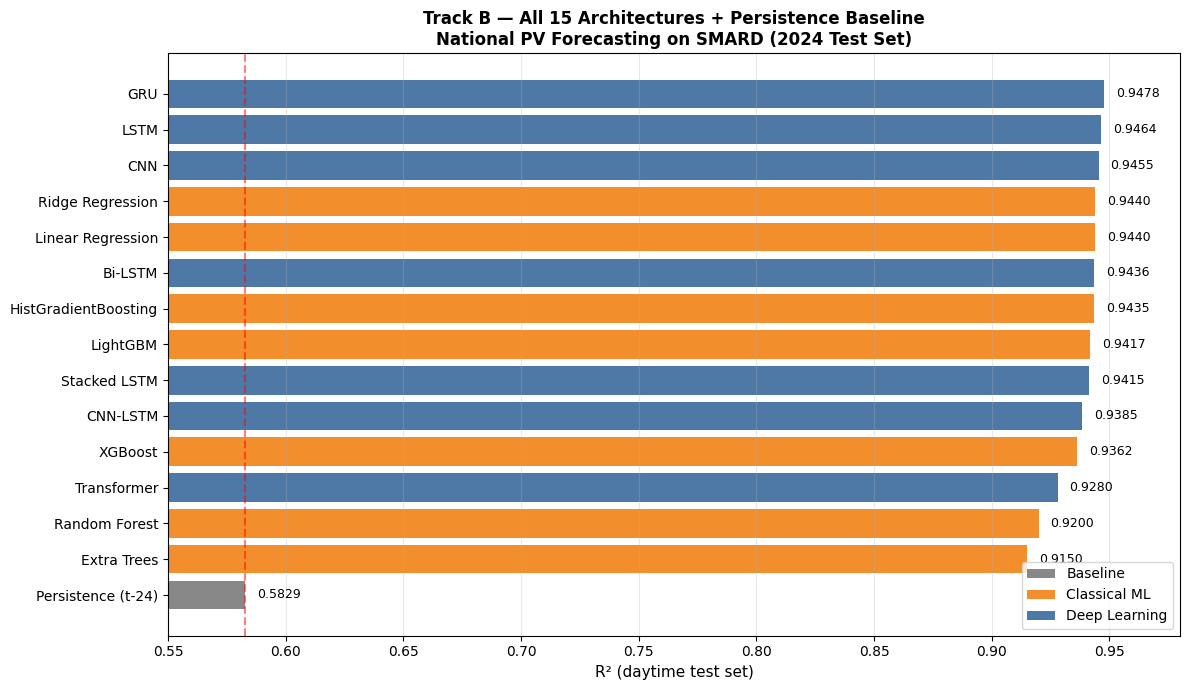

✅ Saved: /content/drive/MyDrive/PV_Thesis/trackB_combined_comparison.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load both result files
ml_df = pd.read_csv("/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/trackB_hourly_ml_results.csv")
dl_df = pd.read_csv("/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Track B SMARD Averaged Data Driven Model/trackB_hourly_dl_results.csv")

# Combine
combined = pd.concat([ml_df, dl_df], ignore_index=True)
combined = combined.sort_values("R² (daytime)", ascending=True)

# Categorize for coloring
def categorize(name):
    if "Persistence" in name:
        return "Baseline"
    elif name in ["CNN", "LSTM", "Stacked LSTM", "Bi-LSTM",
                  "CNN-LSTM", "GRU", "Transformer"]:
        return "Deep Learning"
    else:
        return "Classical ML"

combined["Category"] = combined["Model"].apply(categorize)

# Color mapping
colors_map = {
    "Baseline": "#888888",
    "Classical ML": "#f28e2b",
    "Deep Learning": "#4e79a7"
}
colors = [colors_map[c] for c in combined["Category"]]

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(combined["Model"], combined["R² (daytime)"], color=colors)

# Add R² values at end of bars
for bar, r2 in zip(bars, combined["R² (daytime)"]):
    ax.text(r2 + 0.005, bar.get_y() + bar.get_height()/2,
            f"{r2:.4f}", va="center", fontsize=9)

# Reference line at persistence
persist_r2 = combined.loc[combined["Model"].str.contains("Persistence"), "R² (daytime)"].values[0]
ax.axvline(x=persist_r2, color="red", linestyle="--", alpha=0.5,
           label=f"Persistence baseline (R²={persist_r2:.3f})")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#888888", label="Baseline"),
    Patch(facecolor="#f28e2b", label="Classical ML"),
    Patch(facecolor="#4e79a7", label="Deep Learning"),
]
ax.legend(handles=legend_elements, loc="lower right")

ax.set_xlabel("R² (daytime test set)", fontsize=11)
ax.set_title("Track B — All 15 Architectures + Persistence Baseline\n"
             "National PV Forecasting on SMARD (2024 Test Set)",
             fontsize=12, weight="bold")
ax.set_xlim(0.55, 0.98)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Save
save_path = "/content/drive/MyDrive/PV_Thesis/trackB_combined_comparison.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Saved: {save_path}")